# ICT4SM – Lab 1: Free-floating car sharing analysis
**Group 11 – cities: Torino (City 1), Columbus, Frankfurt** – Car2Go data, analysis period 1 Nov 2017 – 31 Jan 2018.

## 0. Setup

In [ ]:

#!pip install pymongo seaborn scipy holidays
#!pip install contextily folium      # only for the background map / interactive heatmap (section 2.7)

import os, warnings
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymongo as pm
from scipy.ndimage import gaussian_filter1d
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
for d in ("figures", "tables", "cache"):
    os.makedirs(d, exist_ok=True)

# ---------------- group configuration ----------------
MY_CITIES = ["Torino", "Columbus", "Frankfurt"]      # Group 11
CITY1 = MY_CITIES[0]                                 # used in 2.6 and 2.7
TZ = {"Torino": "Europe/Rome", "Frankfurt": "Europe/Berlin", "Columbus": "America/New_York"}
PERIOD = ("2017-11-01 00:00", "2018-02-01 00:00")    # local time, end exclusive (= 31 Jan 23:59:59)
LAST_FULL_DAY = pd.Timestamp("2018-01-30")           # collection ends on 31 Jan ~14:13 CET (08:13 EST) -> that day is incomplete
PALETTE = dict(zip(MY_CITIES, sns.color_palette("tab10", len(MY_CITIES))))

def to_epoch(local_str, city):
    """Local wall-clock string of `city` -> UNIX epoch (UTC seconds). Independent of the machine time zone."""
    return int(pd.Timestamp(local_str, tz=TZ[city]).timestamp())

def period_epochs(city):
    return to_epoch(PERIOD[0], city), to_epoch(PERIOD[1], city)

def savefig(name):
    plt.savefig(f"figures/{name}.png")

In [2]:
client = pm.MongoClient(
    "bigdatadb.polito.it", tls=True, authSource="carsharing",
    username="ictts", password="Ict4SM22!",
    tlsAllowInvalidCertificates=True, serverSelectionTimeoutMS=20000,
)
db = client["carsharing"]

EXPECTED = ["ActiveBookings", "ActiveParkings", "PermanentBookings", "PermanentParkings",
            "enjoy_ActiveBookings", "enjoy_ActiveParkings", "enjoy_PermanentBookings", "enjoy_PermanentParkings"]
available = db.list_collection_names()
COLLS = [c for c in EXPECTED if c in available]
print("Collections found :", COLLS)
print("Collections missing:", [c for c in EXPECTED if c not in available])
PB, PP = db["PermanentBookings"], db["PermanentParkings"]

Collections found : ['ActiveBookings', 'ActiveParkings', 'PermanentBookings', 'PermanentParkings', 'enjoy_ActiveBookings', 'enjoy_ActiveParkings', 'enjoy_PermanentBookings', 'enjoy_PermanentParkings']
Collections missing: []


## Step 1 – Preliminary data analysis (MongoDB queries)
### 1.0 Schema inspection
We never assume field names: we print one document per collection and use only the fields that really exist.

In [3]:
for name in COLLS:
    doc = db[name].find_one()
    print(f"\n=== {name} ===")
    if doc is None:
        print("  (empty)"); continue
    for k, v in doc.items():
        print(f"  {k:24s} {type(v).__name__:10s} {str(v)[:80]}")


=== ActiveBookings ===
  _id                      ObjectId   5a2e8c0d2ad85324ef307f84
  init_fuel                int        39
  city                     str        Austin
  walking                  dict       {'duration': -1, 'distance': -1}
  vendor                   str        car2go
  driving                  dict       {'duration': -1, 'distance': -1}
  final_time               int        -1
  plate                    str        FHB 2898
  engineType               str        CE
  init_time                int        1512999938
  vin                      str        WMEEJ3BA3FK799989
  smartPhoneRequired       bool       False
  interior                 str        GOOD
  final_fuel               int        -1
  exterior                 str        GOOD
  init_date                datetime   2017-12-11 07:45:38
  final_date               int        -1
  init_address             str        4707 Harmon Ave, Austin, TX 78751, USA
  final_address            str        
  origin_destination

### 1.1 Number of documents per collection
`PermanentBookings` and `PermanentParkings` have almost the same size because every car alternates, forever, a *parking* period (car available) and a *booking* period (car rented):
each booking is closed by a parking and each parking by a booking, so the two sequences differ by at most one document per car (plus data-collection gaps).

In [4]:
counts = pd.DataFrame({"documents": {n: db[n].count_documents({}) for n in COLLS}})
display(counts)
for prefix in ("", "enjoy_"):
    b, p = f"{prefix}PermanentBookings", f"{prefix}PermanentParkings"
    if b in counts.index and p in counts.index:
        nb, np_ = counts.loc[b, "documents"], counts.loc[p, "documents"]
        print(f"{prefix or 'car2go_'}: parkings/bookings = {np_/nb:.4f}  (difference = {np_-nb:,} documents)")
counts.to_csv("tables/step1_counts.csv")

,documents
ActiveBookings,8743
ActiveParkings,4790
PermanentBookings,28180508
PermanentParkings,28312676
enjoy_ActiveBookings,0
enjoy_ActiveParkings,0
enjoy_PermanentBookings,6653472
enjoy_PermanentParkings,6689979


car2go_: parkings/bookings = 1.0047  (difference = 132,168 documents)
enjoy_: parkings/bookings = 1.0055  (difference = 36,507 documents)


### 1.2 Cities covered by each collection

In [5]:
presence = {n: set(db[n].distinct("city")) for n in COLLS}
all_cities = sorted(set().union(*presence.values()))
city_matrix = pd.DataFrame({n: [c in presence[n] for c in all_cities] for n in COLLS}, index=all_cities)
display(city_matrix.replace({True: "x", False: ""}))
print("Our cities present in PermanentBookings:", [c for c in MY_CITIES if c in presence["PermanentBookings"]])

,ActiveBookings,ActiveParkings,PermanentBookings,PermanentParkings,enjoy_ActiveBookings,enjoy_ActiveParkings,enjoy_PermanentBookings,enjoy_PermanentParkings
Amsterdam,x,,x,x,,,,
Austin,x,x,x,x,,,,
Berlin,x,,x,x,,,,
Bologna,,,,,,,x,x
Calgary,x,,x,x,,,,
Catania,,,,,,,x,x
Columbus,x,x,x,x,,,,
Denver,x,x,x,x,,,,
Firenze,x,x,x,x,,,x,x
Frankfurt,x,,x,x,,,,


Our cities present in PermanentBookings: ['Torino', 'Columbus', 'Frankfurt']


### 1.3 Start and end of each collection
One single server-side pass (`$group` with `$min`/`$max`) per collection. For the *Active* collections the fields may differ: missing fields simply show up as `NaN`.

In [6]:
def time_range(coll_name, by_city=False, cities=None):
    pipe = []
    if cities: pipe.append({"$match": {"city": {"$in": cities}}})
    pipe.append({"$group": {"_id": "$city" if by_city else None, "n": {"$sum": 1},
                            "first_init": {"$min": "$init_time"}, "last_init": {"$max": "$init_time"},
                            "last_final": {"$max": "$final_time"}}})
    res = list(db[coll_name].aggregate(pipe, allowDiskUse=True))
    if not res:                                   # empty collection (or no documents for these cities)
        return pd.DataFrame()
    df = pd.DataFrame(res).rename(columns={"_id": "city"})
    for c in ("first_init", "last_init", "last_final"):
        if c in df: df[c] = pd.to_datetime(df[c], unit="s", utc=True)
    return df

frames = {n: time_range(n) for n in COLLS}
print("Empty collections:", [n for n, f in frames.items() if f.empty])
glob = pd.concat({n: f.drop(columns="city", errors="ignore") for n, f in frames.items() if not f.empty}).droplevel(1)
display(glob)
per_city = pd.concat({n: time_range(n, by_city=True, cities=MY_CITIES) for n in ("PermanentBookings", "PermanentParkings")}).droplevel(1)
display(per_city)
glob.to_csv("tables/step1_time_range.csv")

Empty collections: ['enjoy_ActiveBookings', 'enjoy_ActiveParkings']


,n,first_init,last_init,last_final
ActiveBookings,8743,2017-12-11 13:45:38+00:00,2018-01-31 13:13:03+00:00,1969-12-31 23:59:59+00:00
ActiveParkings,4790,2018-01-24 05:56:00+00:00,2018-01-31 13:13:03+00:00,1969-12-31 23:59:59+00:00
PermanentBookings,28180508,2016-12-13 17:38:23+00:00,2018-01-31 13:11:33+00:00,2018-01-31 13:13:03+00:00
PermanentParkings,28312676,2016-12-13 17:37:38+00:00,2018-01-31 13:11:33+00:00,2018-01-31 13:13:03+00:00
enjoy_PermanentBookings,6653472,2017-05-05 15:06:21+00:00,2019-06-10 17:16:20+00:00,2019-06-10 17:20:35+00:00
enjoy_PermanentParkings,6689979,2017-05-05 15:05:36+00:00,2019-06-10 17:16:20+00:00,2019-06-10 17:20:35+00:00


,city,n,first_init,last_init,last_final
PermanentBookings,Torino,873240,2016-12-13 17:38:23+00:00,2018-01-31 13:09:55+00:00,2018-01-31 13:13:03+00:00
PermanentBookings,Frankfurt,507420,2016-12-13 17:38:23+00:00,2018-01-31 13:04:44+00:00,2018-01-31 13:11:33+00:00
PermanentBookings,Columbus,187687,2016-12-13 17:43:46+00:00,2018-01-31 13:10:45+00:00,2018-01-31 13:13:03+00:00
PermanentParkings,Torino,875472,2016-12-13 17:37:38+00:00,2018-01-31 13:07:20+00:00,2018-01-31 13:13:03+00:00
PermanentParkings,Columbus,188836,2016-12-13 17:37:38+00:00,2018-01-31 13:07:20+00:00,2018-01-31 13:13:03+00:00
PermanentParkings,Frankfurt,510162,2016-12-13 17:37:38+00:00,2018-01-31 13:11:33+00:00,2018-01-31 13:13:03+00:00


### 1.4 Time zone of `init_time` / `init_date`
`init_time` is a UNIX epoch (UTC by definition). `init_date` is a human-readable timestamp: we measure the offset between `init_date` read as if it were UTC and the true UTC instant given by `init_time`, on a random sample for each of our cities.

**Result:** the offset is +1 h / +2 h for Torino and Frankfurt (CET / CEST) and −5 h / −4 h for Columbus (EST / EDT). Hence `init_date` is the **local wall-clock time of each city, including daylight-saving changes**, whereas `init_time` is UTC. We always start from `init_time` and convert it with `zoneinfo`, which is unambiguous and handles DST.

In [7]:
tz_rows = []
for city in MY_CITIES:
    s = pd.DataFrame(list(PB.aggregate([{"$match": {"city": city}}, {"$sample": {"size": 4000}},
                                        {"$project": {"_id": 0, "init_time": 1, "init_date": 1}}], allowDiskUse=True)))
    naive_utc = pd.to_datetime(s["init_time"], unit="s")
    off = ((pd.to_datetime(s["init_date"]) - naive_utc).dt.total_seconds() / 3600).round()
    tz_rows.append(off.value_counts().rename(city))
tz_check = pd.concat(tz_rows, axis=1).fillna(0).astype(int)
tz_check.index.name = "init_date - UTC [hours]"
display(tz_check)

,Torino,Columbus,Frankfurt
init_date - UTC [hours],,,
1.0,2162,0,2061
2.0,1838,0,1939
-4.0,0,2115,0
-5.0,0,1885,0


### 1.5 Number of cars and fleet size
* **Total distinct plates** in the whole collection (bookings and parkings) – an *upper bound* of the fleet, because cars are added/removed/replaced over 14 months.
* **Weekly fleet estimate**: plates observed in a given week (union of bookings and parkings, so that cars that were never rented in that week still count). Weeks are 7-day bins anchored on Monday 00:00 UTC.

,distinct plates (bookings),distinct plates (parkings),distinct plates (union of weekly sets)
Torino,609,609,609
Columbus,215,215,215
Frankfurt,304,304,304


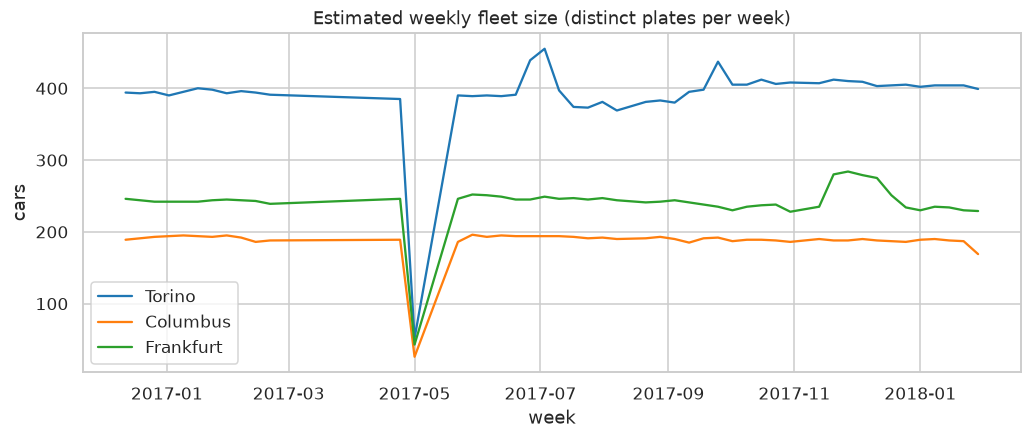

,"median weekly fleet (Nov-Jan, complete weeks)",min,max,total distinct plates,weekly / total
Torino,404.5,402.0,412.0,609.0,0.66
Columbus,188.0,186.0,190.0,215.0,0.87
Frankfurt,243.0,230.0,284.0,304.0,0.80


In [8]:
ANCHOR = int(pd.Timestamp("2016-12-12", tz="UTC").timestamp())     # a Monday
WEEK = 7 * 86400

def distinct_plates(coll, city):
    r = list(coll.aggregate([{"$match": {"city": city}}, {"$group": {"_id": "$plate"}}, {"$count": "n"}], allowDiskUse=True))
    return r[0]["n"] if r else 0

def week_plate_pairs(coll, city):
    pipe = [{"$match": {"city": city}},
            {"$group": {"_id": {"w": {"$floor": {"$divide": [{"$subtract": ["$init_time", ANCHOR]}, WEEK]}}, "p": "$plate"}}}]
    return pd.DataFrame([{"week": r["_id"]["w"], "plate": r["_id"]["p"]} for r in coll.aggregate(pipe, allowDiskUse=True)])

tot, weekly = {}, {}
for c in MY_CITIES:
    pairs = pd.concat([week_plate_pairs(PB, c), week_plate_pairs(PP, c)]).drop_duplicates()
    weekly[c] = pairs.groupby("week").plate.nunique()
    tot[c] = {"distinct plates (bookings)": distinct_plates(PB, c),
              "distinct plates (parkings)": distinct_plates(PP, c),
              "distinct plates (union of weekly sets)": pairs.plate.nunique()}
display(pd.DataFrame(tot).T)

fig, ax = plt.subplots(figsize=(11, 4))
for c in MY_CITIES:
    w = weekly[c]
    ax.plot(pd.to_datetime(ANCHOR + w.index.values * WEEK, unit="s"), w.values, label=c, color=PALETTE[c])
ax.set(title="Estimated weekly fleet size (distinct plates per week)", ylabel="cars", xlabel="week")
ax.legend(); savefig("step1_weekly_fleet"); plt.show()

w_in = {c: weekly[c][(ANCHOR + weekly[c].index * WEEK >= to_epoch(PERIOD[0], c)) & (ANCHOR + (weekly[c].index + 1) * WEEK <= to_epoch("2018-01-29 00:00", c))]
        for c in MY_CITIES}
fleet_summary = pd.DataFrame({c: {"median weekly fleet (Nov-Jan, complete weeks)": w_in[c].median(),
                                  "min": w_in[c].min(), "max": w_in[c].max(),
                                  "total distinct plates": tot[c]["distinct plates (union of weekly sets)"]} for c in MY_CITIES}).T
fleet_summary["weekly / total"] = (fleet_summary.iloc[:, 0] / fleet_summary["total distinct plates"]).round(2)
display(fleet_summary); fleet_summary.to_csv("tables/step1_fleet.csv")

### 1.6 Bookings in December 2017
Month boundaries are the *local* midnights of each city (1 Dec 00:00 → 1 Jan 00:00 local).

In [9]:
dec = []
for c in MY_CITIES:
    a, b = to_epoch("2017-12-01 00:00", c), to_epoch("2018-01-01 00:00", c)
    dec.append({"city": c, "bookings Dec-2017": PB.count_documents({"city": c, "init_time": {"$gte": a, "$lt": b}})})
dec = pd.DataFrame(dec).set_index("city"); display(dec); dec.to_csv("tables/step1_december.csv")

,bookings Dec-2017
city,
Torino,95586
Columbus,20751
Frankfurt,53944


### 1.7 Bookings with alternative-transport information
Schema inspection (1.0) shows that `walking`, `driving` and `public_transport` are **always present**, with `duration = -1` (and `distance = -1`) when Google Maps was not queried. A plain `$exists` / `$type` test would therefore count 100 % of the bookings.
A booking "has" an alternative only if the corresponding `*.duration` is numeric **and > 0**. One server-side pass per city, whole collection and Nov–Jan period.

In [10]:
NUM = ["double", "int", "long", "decimal"]
def has_num(field):
    """Counts documents where the field is numeric AND > 0 (the DB uses -1 as 'not available')."""
    return {"$sum": {"$cond": [{"$and": [{"$in": [{"$type": f"${field}"}, NUM]}, {"$gt": [f"${field}", 0]}]}, 1, 0]}}

def alt_counts(city, period_only):
    match = {"city": city}
    if period_only:
        a, b = period_epochs(city); match["init_time"] = {"$gte": a, "$lt": b}
    r = list(PB.aggregate([{"$match": match}, {"$group": {"_id": None, "total bookings": {"$sum": 1},
              "public transport": has_num("public_transport.duration"),
              "walking": has_num("walking.duration"),
              "driving": has_num("driving.duration")}}], allowDiskUse=True))
    return {k: v for k, v in r[0].items() if k != "_id"} if r else {}

alt_all = pd.DataFrame({c: alt_counts(c, False) for c in MY_CITIES}).T
alt_per = pd.DataFrame({c: alt_counts(c, True) for c in MY_CITIES}).T
for t in (alt_all, alt_per):
    for m in ("public transport", "walking", "driving"):
        t[f"{m} [%]"] = (100 * t[m] / t["total bookings"]).round(1)
print("Whole collection"); display(alt_all)
print("Analysis period (Nov 2017 - Jan 2018)"); display(alt_per)
alt_all.to_csv("tables/step1_alt_all.csv"); alt_per.to_csv("tables/step1_alt_period.csv")

Whole collection


,total bookings,public transport,walking,driving,public transport [%],walking [%],driving [%]
Torino,873240,261629,296447,296138,30.0,33.9,33.9
Columbus,187687,0,0,0,0.0,0.0,0.0
Frankfurt,507420,0,0,0,0.0,0.0,0.0


Analysis period (Nov 2017 - Jan 2018)


,total bookings,public transport,walking,driving,public transport [%],walking [%],driving [%]
Torino,264672,63266,72737,72678,23.9,27.5,27.5
Columbus,52885,0,0,0,0.0,0.0,0.0
Frankfurt,146591,0,0,0,0.0,0.0,0.0


## Step 2 – Car sharing usage characterisation
### 2.0 Data loading and feature engineering
For each city we download only the needed fields for 1 Nov 2017 – 31 Jan 2018 (local time) and compute:
duration, local start time (date, hour, weekday), straight-line origin→destination distance (haversine) and average straight-line speed.
Parkings are loaded with a 30-day margin *before* the period, so that the number of parked cars at the beginning of November is not underestimated; `in_period` marks the rows that really start inside the period (statistics use only those; occupancy uses all).
Data are cached in `cache/` to avoid re-downloading (files are versioned with `CACHE_TAG`: change it if you modify the loaders).

In [11]:
CACHE_TAG = "v4"      # bump this string whenever the loaders change: old cache files are then ignored automatically
CLEAN_LOG = []
inp = lambda d: d[d["in_period"]]          # rows that start inside the analysis period

def col(raw, name):
    return pd.to_numeric(raw[name], errors="coerce") if name in raw else pd.Series(np.nan, index=raw.index)

def _coord(c, i, j):
    try:
        v = float(c[i][j])
        return np.nan if v == -1.0 else v          # -1 is the "not available" sentinel
    except Exception:
        return np.nan

def dur_min(raw, name):
    v = col(raw, name)
    return v.where(v > 0) / 60                      # -1 (not available) -> NaN; seconds -> minutes

def add_time_features(d, city, kind):
    n_raw = len(d)
    d = d.dropna(subset=["t0", "t1"]).copy()
    d[["t0", "t1"]] = d[["t0", "t1"]].astype("int64")
    d = d[d.t1 > d.t0].copy()
    CLEAN_LOG.append({"city": city, "kind": kind, "downloaded": n_raw, "dropped (missing time or end<=start)": n_raw - len(d)})
    d["dur_min"] = (d.t1 - d.t0) / 60
    loc = pd.to_datetime(d.t0, unit="s", utc=True).dt.tz_convert(TZ[city]).dt.tz_localize(None)   # local wall-clock time
    d["start"], d["date"] = loc, loc.dt.normalize()
    d["hour"], d["dow"] = loc.dt.hour, loc.dt.dayofweek
    d["weekend"] = d.dow >= 5
    d["week"] = d.date - pd.to_timedelta(d.dow, unit="D")
    a, b = period_epochs(city)
    d["in_period"] = (d.t0 >= a) & (d.t0 < b)
    return d.reset_index(drop=True)

def haversine_km(lat0, lon0, lat1, lon1):
    p = np.pi / 180
    a = np.sin((lat1 - lat0) * p / 2) ** 2 + np.cos(lat0 * p) * np.cos(lat1 * p) * np.sin((lon1 - lon0) * p / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(a))

def docs_to_bookings(docs, city):
    raw = pd.json_normalize(docs)
    d = pd.DataFrame({"city": city, "plate": raw["plate"], "t0": col(raw, "init_time"), "t1": col(raw, "final_time"),
                      "pt_min": dur_min(raw, "public_transport.duration"),
                      "walk_min": dur_min(raw, "walking.duration"),
                      "drive_min": dur_min(raw, "driving.duration")})
    oc = raw["origin_destination.coordinates"] if "origin_destination.coordinates" in raw else pd.Series([None] * len(raw))
    d["lon0"], d["lat0"] = [_coord(c, 0, 0) for c in oc], [_coord(c, 0, 1) for c in oc]
    d["lon1"], d["lat1"] = [_coord(c, 1, 0) for c in oc], [_coord(c, 1, 1) for c in oc]
    d = add_time_features(d, city, "bookings")
    d["dist_km"] = haversine_km(d.lat0, d.lon0, d.lat1, d.lon1)
    d["speed_kmh"] = d.dist_km / (d.dur_min / 60)
    return d

def docs_to_parkings(docs, city):
    raw = pd.json_normalize(docs)
    d = pd.DataFrame({"city": city, "plate": raw["plate"], "t0": col(raw, "init_time"), "t1": col(raw, "final_time")})
    return add_time_features(d, city, "parkings")

BOOK_PROJ = {"_id": 0, "city": 1, "plate": 1, "init_time": 1, "final_time": 1, "origin_destination": 1,
             "public_transport.duration": 1, "walking.duration": 1, "driving.duration": 1}
PARK_PROJ = {"_id": 0, "city": 1, "plate": 1, "init_time": 1, "final_time": 1}

def load_bookings(city, force=False):
    path = f"cache/bookings_{city}_{CACHE_TAG}.pkl"
    if os.path.exists(path) and not force: return pd.read_pickle(path)
    a, b = period_epochs(city)
    d = docs_to_bookings(list(PB.find({"city": city, "init_time": {"$gte": a - 86400, "$lt": b}}, BOOK_PROJ)), city)
    d.to_pickle(path); return d

def load_parkings(city, force=False):
    path = f"cache/parkings_{city}_{CACHE_TAG}.pkl"
    if os.path.exists(path) and not force: return pd.read_pickle(path)
    a, b = period_epochs(city)
    d = docs_to_parkings(list(PP.find({"city": city, "init_time": {"$gte": a - 30 * 86400, "$lt": b}}, PARK_PROJ)), city)
    d.to_pickle(path); return d

In [12]:
CLEAN_LOG.clear()
B = {c: load_bookings(c) for c in MY_CITIES}
P = {c: load_parkings(c) for c in MY_CITIES}
summary = pd.DataFrame({
    "bookings in period": {c: int(B[c].in_period.sum()) for c in MY_CITIES},
    "bookings w/o coordinates": {c: int(inp(B[c]).dist_km.isna().sum()) for c in MY_CITIES},
    "bookings with PT info": {c: int((inp(B[c]).pt_min > 0).sum()) for c in MY_CITIES},
    "parkings in period": {c: int(P[c].in_period.sum()) for c in MY_CITIES}})
display(summary)
display(pd.DataFrame(CLEAN_LOG).drop_duplicates())

,bookings in period,bookings w/o coordinates,bookings with PT info,parkings in period
Torino,264672,0,63266,264706
Columbus,52885,0,0,52832
Frankfurt,146591,0,0,146878


""


### 2.0b Data-collection gaps and fleet size
The scraper can stop for hours/days. Days with an abnormally low number of bookings (< 25 % of the median of the same day-of-week, plus partial days next to a gap, < 60 %) are flagged and **excluded from time-of-day statistics**, otherwise a system outage would be mistaken for a drop in demand.
The fleet size used to normalise occupancy is the median number of distinct plates per complete week (bookings ∪ parkings), as in section 1.5.

Torino     flagged outage days: ['2017-11-02', '2017-11-03', '2017-11-04', '2017-11-05', '2017-11-06', '2017-11-07', '2017-11-08', '2017-11-09', '2017-11-10', '2017-11-11', '2017-11-12', '2017-12-10', '2017-12-11']
Columbus   flagged outage days: ['2017-11-02', '2017-11-03', '2017-11-04', '2017-11-05', '2017-11-06', '2017-11-07', '2017-11-08', '2017-11-09', '2017-11-10', '2017-11-11', '2017-11-12', '2017-12-10']
Frankfurt  flagged outage days: ['2017-11-02', '2017-11-03', '2017-11-04', '2017-11-05', '2017-11-06', '2017-11-07', '2017-11-08', '2017-11-09', '2017-11-10', '2017-11-11', '2017-11-12', '2017-12-10', '2017-12-11']


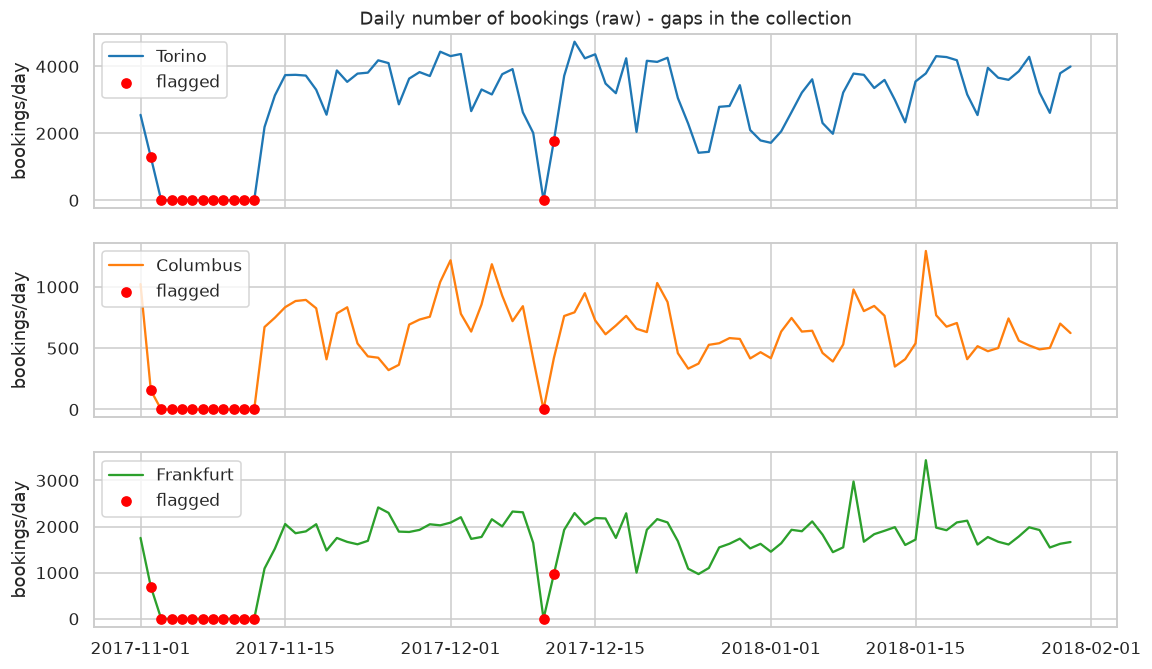

Fleet used for normalisation: {'Torino': 404.0, 'Columbus': 188.0, 'Frankfurt': 235.0}


In [13]:
OUTAGE, daily_n = {}, {}
for c in MY_CITIES:
    n = inp(B[c]).groupby("date").size()
    n = n.reindex(pd.date_range(PERIOD[0], LAST_FULL_DAY), fill_value=0)
    med = n.groupby(n.index.dayofweek).transform("median")
    bad = set(n.index[n < 0.25 * med])
    changed = True
    while changed:                                  # partial days at the edges of a gap (< 60 % of normal)
        changed = False
        for d in sorted(bad):
            for nb in (d - pd.Timedelta(days=1), d + pd.Timedelta(days=1)):
                if nb in n.index and nb not in bad and n[nb] < 0.6 * med[nb]:
                    bad.add(nb); changed = True
    OUTAGE[c] = bad
    daily_n[c] = n
    print(f"{c:10s} flagged outage days: {sorted(d.strftime('%Y-%m-%d') for d in OUTAGE[c]) or 'none'}")

fig, axs = plt.subplots(len(MY_CITIES), 1, figsize=(12, 7), sharex=True)
for ax, c in zip(axs, MY_CITIES):
    ax.plot(daily_n[c].index, daily_n[c].values, color=PALETTE[c], label=c)
    bad = sorted(OUTAGE[c]); ax.scatter(bad, daily_n[c].loc[bad], color="red", zorder=3, label="flagged")
    ax.set_ylabel("bookings/day"); ax.legend(loc="upper left")
axs[0].set_title("Daily number of bookings (raw) - gaps in the collection"); savefig("step2_daily_counts"); plt.show()

def fleet_estimate(city):
    b, p = inp(B[city])[["plate", "week"]], inp(P[city])[["plate", "week"]]
    w = pd.concat([b, p]).drop_duplicates().groupby("week").plate.nunique()
    last = max(inp(B[city]).start.max(), inp(P[city]).start.max()).normalize()
    full = w[(w.index >= pd.Timestamp(PERIOD[0])) & (w.index + pd.Timedelta(days=7) <= last)]
    gap_weeks = {d - pd.Timedelta(days=d.dayofweek) for d in OUTAGE[city]}      # weeks touched by a collection gap
    full = full[~full.index.isin(gap_weeks)]
    return float(full.median()) if len(full) else float(w.max())
FLEET = {c: fleet_estimate(c) for c in MY_CITIES}
print("Fleet used for normalisation:", FLEET)

### 2.1 Distribution of booking / parking durations (empirical CDF, unfiltered)
No filter is applied here (only impossible rows, `final_time <= init_time`, are removed in 2.0) so that outliers stay visible: the x axis is logarithmic and covers the entire range.

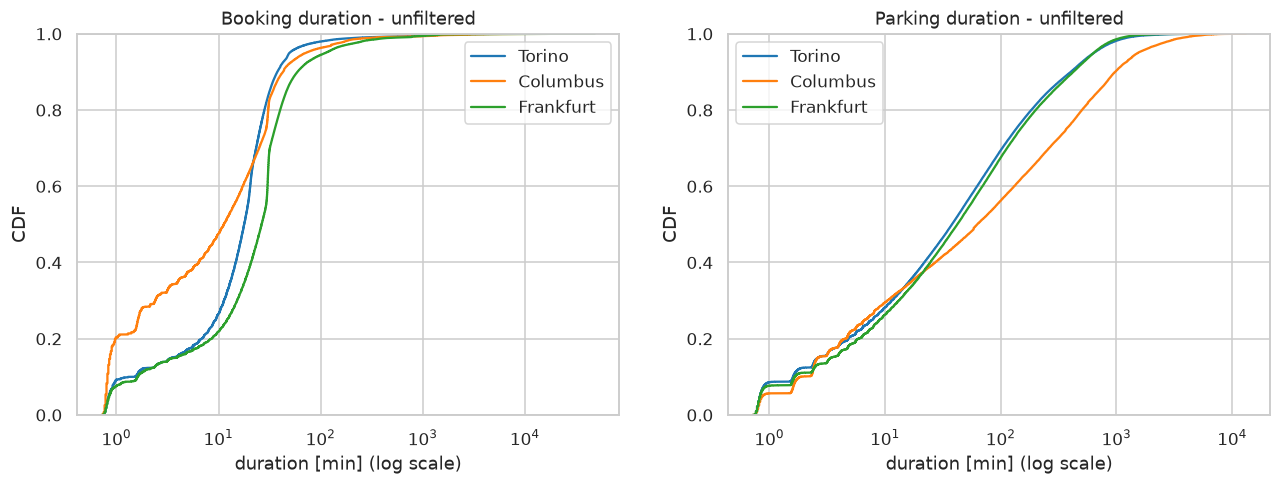

Booking duration percentiles [min]


,0.010,0.050,0.250,0.500,0.750,0.900,0.950,0.990,0.999
Torino,0.8,0.8,9.4,17.8,25.5,37.7,49.6,247.2,2473.3
Columbus,0.8,0.8,1.6,11.3,29.3,42.8,71.9,337.4,4293.1
Frankfurt,0.8,0.8,12.2,26.4,35.6,59.3,111.9,541.4,2932.9


Parking duration percentiles [min]


,0.010,0.050,0.250,0.500,0.750,0.900,0.950,0.990,0.999
Torino,0.8,0.8,7.8,37.9,135.3,402.4,639.1,1245.0,3004.8
Columbus,0.8,0.9,6.7,62.6,367.5,974.2,1533.0,3783.4,7280.3
Frankfurt,0.8,0.8,9.0,42.2,148.1,423.8,636.4,1118.3,2341.2


Longest booking [h]: {'Torino': 792.7, 'Columbus': 667.7, 'Frankfurt': 806.7}
Longest parking [days]: {'Torino': 6.2, 'Columbus': 9.1, 'Frankfurt': 5.2}


In [14]:
Q = (.01, .05, .25, .5, .75, .9, .95, .99, .999)
def pct_table(dfs, col="dur_min"):
    return pd.DataFrame({c: inp(d)[col].quantile(Q) for c, d in dfs.items()}).T.round(1)

def cdf_cities(dfs, ax, title):
    for c, d in dfs.items():
        sns.ecdfplot(data=inp(d), x="dur_min", log_scale=True, ax=ax, label=c, color=PALETTE[c])
    ax.set(title=title, xlabel="duration [min] (log scale)", ylabel="CDF"); ax.legend()

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
cdf_cities(B, axs[0], "Booking duration - unfiltered"); cdf_cities(P, axs[1], "Parking duration - unfiltered")
savefig("step2_1_cdf_unfiltered"); plt.show()
print("Booking duration percentiles [min]"); display(pct_table(B))
print("Parking duration percentiles [min]"); display(pct_table(P))
print("Longest booking [h]:", {c: round(inp(B[c]).dur_min.max() / 60, 1) for c in MY_CITIES})
print("Longest parking [days]:", {c: round(inp(P[c]).dur_min.max() / 1440, 1) for c in MY_CITIES})

**What to look for (comments for the report):**
(a) which city has the longest durations and whether this is plausible (city size, tariffs, car2go price caps);
whether the far right tail (hours/days) and the mass at < 1–2 min reveal system artefacts;
(b) the *steps* in the CDFs (e.g. at 20 or 30 min): a step means that many bookings end at exactly the same duration, which is the signature of reservations that expire automatically, not of real trips – this is verified quantitatively in 2.3.

#### 2.1c Does the CDF change over time? (per week and weekday vs weekend)

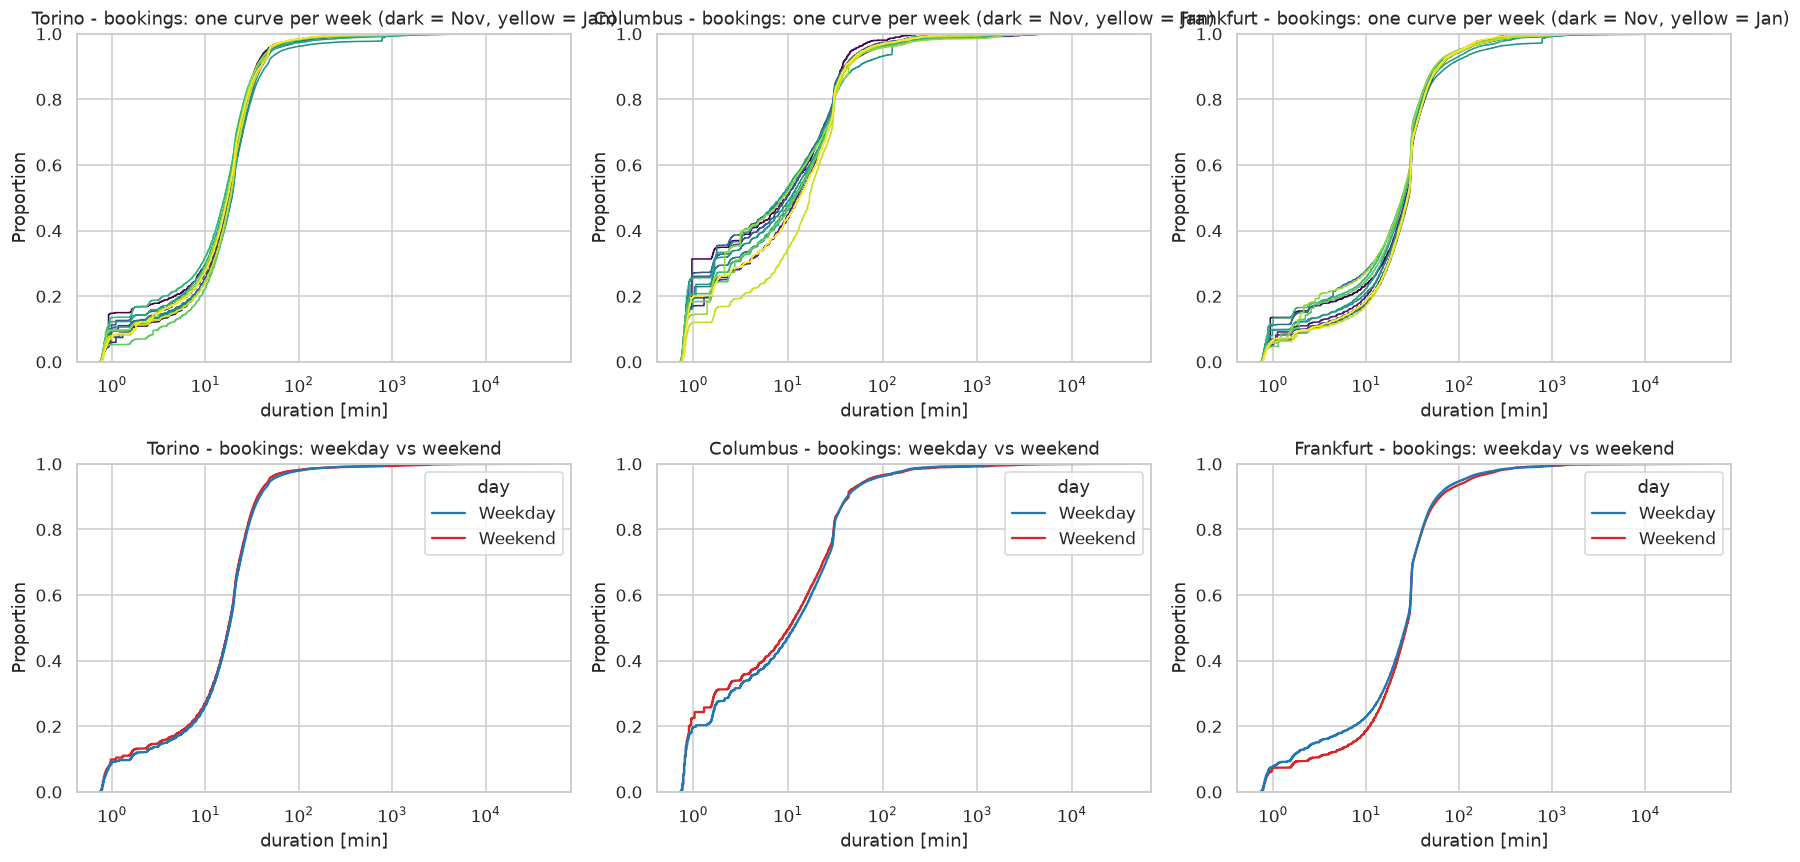

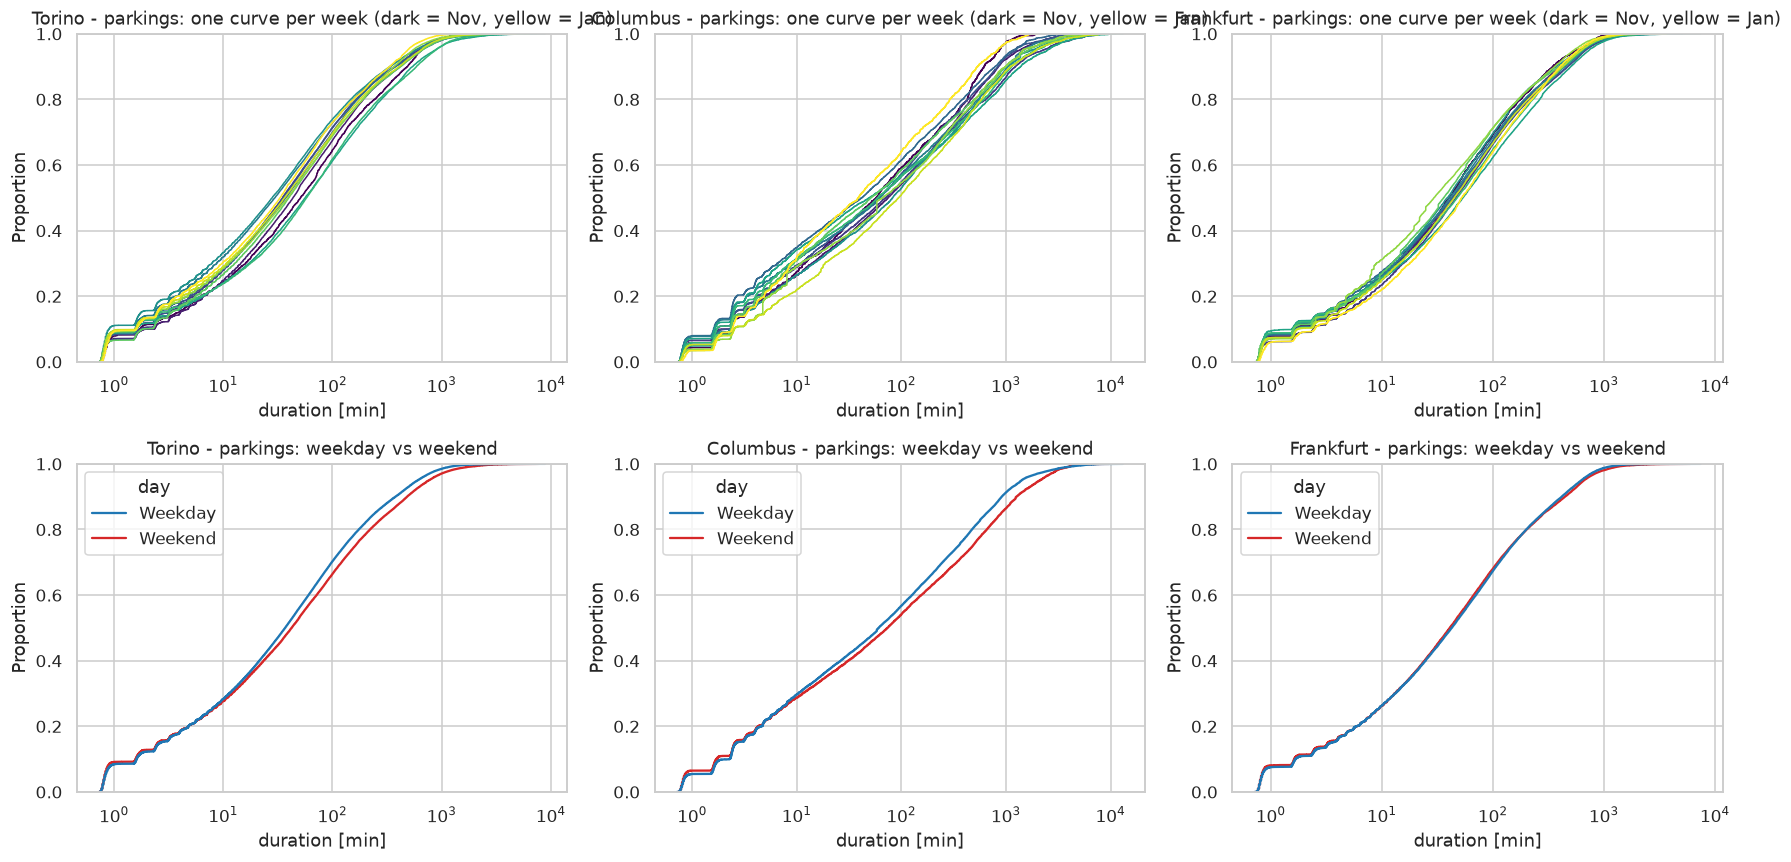

In [15]:
def cdf_over_time(dfs, kind):
    fig, axs = plt.subplots(2, len(dfs), figsize=(16, 8))
    for k, (c, d) in enumerate(dfs.items()):
        d = inp(d); weeks = sorted(d.week.unique()); cmap = plt.get_cmap("viridis")
        for i, w in enumerate(weeks):
            sub = d[d.week == w]
            if len(sub) > 200:
                sns.ecdfplot(data=sub, x="dur_min", log_scale=True, ax=axs[0, k], color=cmap(i / max(len(weeks) - 1, 1)), lw=1)
        axs[0, k].set(title=f"{c} - {kind}: one curve per week (dark = Nov, yellow = Jan)", xlabel="duration [min]")
        sns.ecdfplot(data=d.assign(day=np.where(d.weekend, "Weekend", "Weekday")), x="dur_min", hue="day",
                     log_scale=True, ax=axs[1, k], palette={"Weekday": "tab:blue", "Weekend": "tab:red"})
        axs[1, k].set(title=f"{c} - {kind}: weekday vs weekend", xlabel="duration [min]")
    plt.tight_layout(); return fig
cdf_over_time(B, "bookings"); savefig("step2_1c_cdf_time_bookings"); plt.show()
cdf_over_time(P, "parkings"); savefig("step2_1c_cdf_time_parkings"); plt.show()

### 2.2 System utilisation over the day (unfiltered)
"Number of booked/parked cars at hour *h*" is computed as the **occupancy**: how many cars are in a booking (parking) state at each instant, sampled every 10 minutes, then averaged by local hour of day, separately for weekdays and weekends, and divided by the fleet size (percentage of the fleet).
This differs from simply counting the bookings that *start* in each hour, which measures demand, not utilisation.
Collection-outage days are excluded.

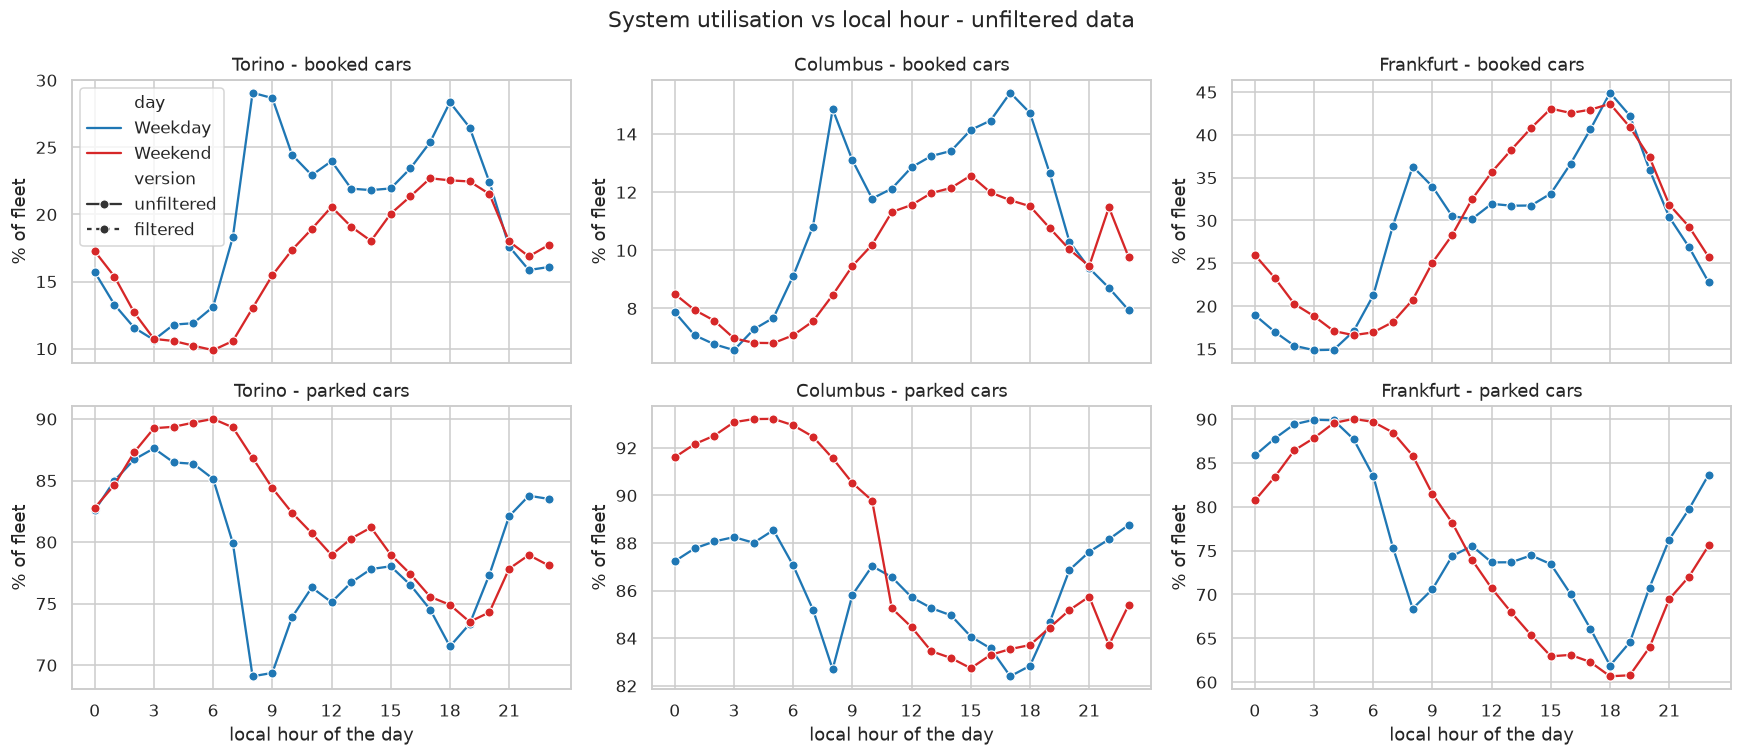

Max booked / parked percentage over the period (>100 % = overlapping intervals, i.e. data problems):


kind,booked,parked
city,,
Columbus,15.4,93.2
Frankfurt,44.9,90.0
Torino,29.1,90.0


In [16]:
def occupancy(df, city, step=600):
    a, b = period_epochs(city)
    b = min(b, to_epoch("2018-01-31 00:00", city))                       # collection ends on 31 Jan morning
    grid = np.arange(a, b, step)
    s, e = np.sort(df.t0.values), np.sort(df.t1.values)
    n = np.searchsorted(s, grid, side="right") - np.searchsorted(e, grid, side="right")
    loc = pd.to_datetime(grid, unit="s", utc=True).tz_convert(TZ[city]).tz_localize(None)
    out = pd.DataFrame({"time": loc, "n": n})
    return out[~out.time.dt.normalize().isin(OUTAGE[city])]

def profiles(Bd, Pd, label):
    res = []
    for c in MY_CITIES:
        for kind, dd in (("booked", Bd[c]), ("parked", Pd[c])):
            o = occupancy(dd, c); o["pct"] = 100 * o.n / FLEET[c]
            o["hour"], o["day"] = o.time.dt.hour, np.where(o.time.dt.dayofweek >= 5, "Weekend", "Weekday")
            g = o.groupby(["day", "hour"]).pct.mean().reset_index(); g["city"], g["kind"], g["version"] = c, kind, label
            res.append(g)
    return pd.concat(res)

def plot_profiles(prof, title, fname):
    fig, axs = plt.subplots(2, len(MY_CITIES), figsize=(16, 7), sharex=True)
    for r, kind in enumerate(("booked", "parked")):
        for k, c in enumerate(MY_CITIES):
            sub = prof[(prof.city == c) & (prof.kind == kind)]
            sns.lineplot(data=sub, x="hour", y="pct", hue="day", style="version", errorbar=None, ax=axs[r, k],
                         palette={"Weekday": "tab:blue", "Weekend": "tab:red"}, markers={"unfiltered": "o", "filtered": "o"},
                         dashes={"unfiltered": "", "filtered": (2, 2)}, style_order=["unfiltered", "filtered"], legend=(r == 0 and k == 0))
            axs[r, k].set(title=f"{c} - {kind} cars", ylabel="% of fleet", xlabel="local hour of the day"); axs[r, k].set_xticks(range(0, 24, 3))
    fig.suptitle(title); plt.tight_layout(); savefig(fname); plt.show()

prof_raw = profiles(B, P, "unfiltered")
plot_profiles(prof_raw, "System utilisation vs local hour - unfiltered data", "step2_2_utilisation_unfiltered")
print("Max booked / parked percentage over the period (>100 % = overlapping intervals, i.e. data problems):")
display(prof_raw.groupby(["city", "kind"]).pct.max().unstack().round(1))

### 2.3 Criterion to obtain *rentals* from *bookings* (data-driven thresholds)
A *booking* is not necessarily a *rental*: the car2go reservation system also records reservations that are cancelled or expire without the car moving, and tracking glitches. A real rental satisfies simultaneously:

| Rule | Rationale | How the threshold is chosen |
|---|---|---|
| **R1** `duration ≥ T_MIN` | shorter than ~1 min cannot be a trip: the CDFs show that 5–10 % of the bookings last ≈ 0.8 min, i.e. they are visible in a single scraper snapshot (glitches / immediate cancellations) | fixed, 1 min |
| **R2** `distance ≥ d_min` | the car must have moved: origin ≠ destination | **valley of the bimodal distribution of log-distance** (GPS-noise/no-movement peak vs. real trips), per city |
| **R3** `average straight-line speed ≤ V_MAX` | physically impossible speeds = timestamp/GPS errors | fixed, 120 km/h |
| **R4** `duration ≤ T_max` | cars kept booked / forgotten / blocked are not urban trips | **99.5th percentile of the duration of moving bookings**, per city, capped at 24 h |

Why not the IQR rule (Q3 + 1.5·IQR)? For heavy-tailed distributions it is always *too tight* (it removes real long trips, ~20 % of all data in a first attempt) and it cannot detect artefacts concentrated *inside* the bulk of the distribution (e.g. the 20/30-minute reservation timeouts).
Parameters are collected in `PARAMS` / `*_OVERRIDE` so that they can be changed in a single place.

Torino     d_min = 50 m | no-movement bookings: 71,951 (27.2 %) | most frequent duration of these: 1.0 min
Columbus   d_min = 50 m | no-movement bookings: 28,285 (53.5 %) | most frequent duration of these: 1.0 min
Frankfurt  d_min = 50 m | no-movement bookings: 55,751 (38.0 %) | most frequent duration of these: 1.0 min


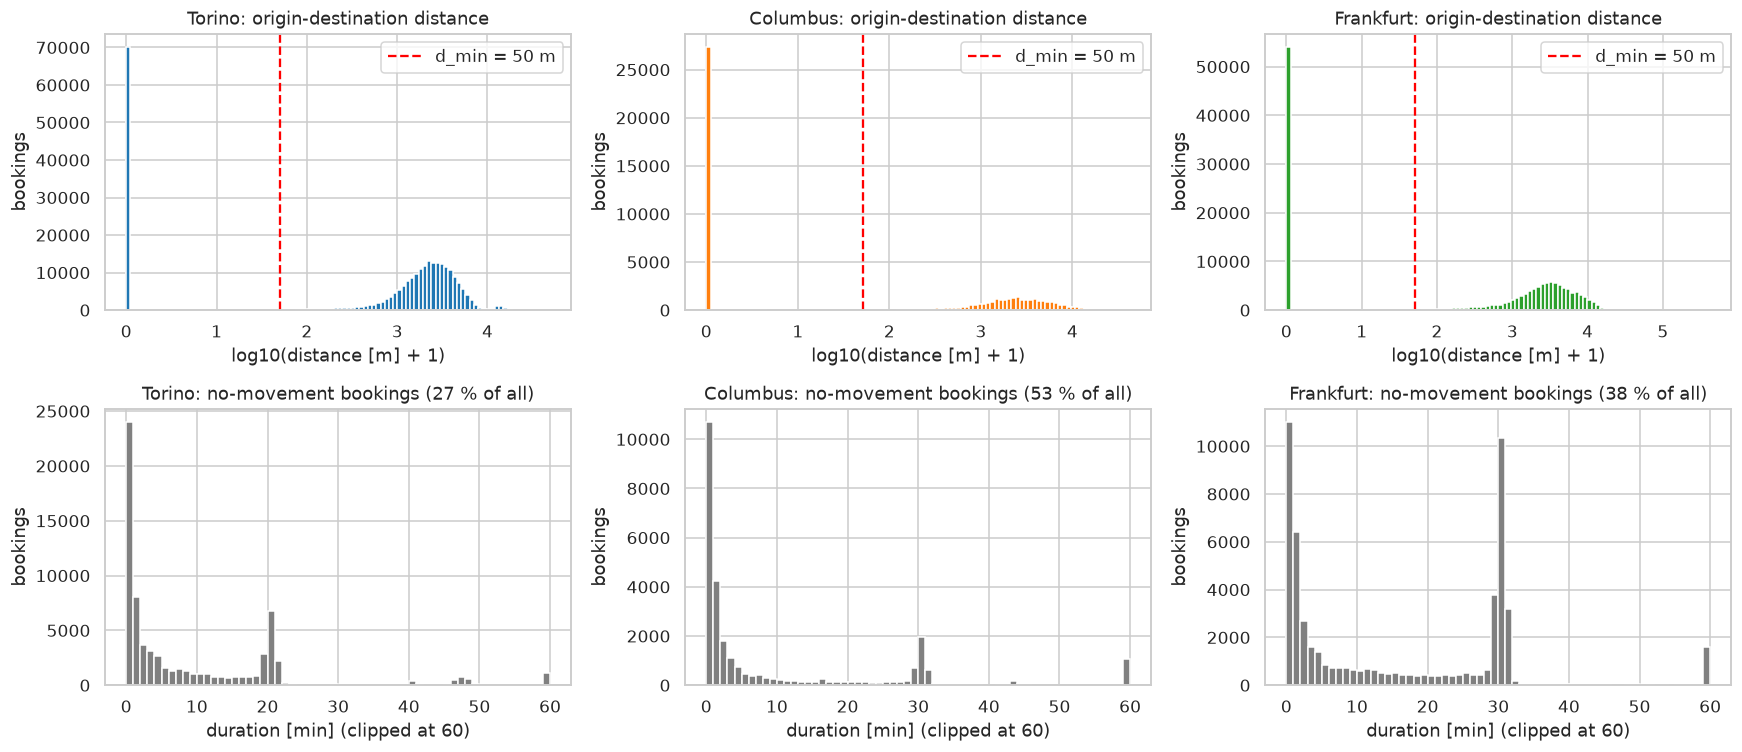

In [17]:
PARAMS = dict(T_MIN=1.0, V_MAX=120.0, T_MAX_PCT=99.5, T_MAX_CAP_MIN=24 * 60, P_MIN=1.0, P_MAX_PCT=None)   # P_MAX_PCT=None: no upper cut on parkings (see below); e.g. 99.9 to cut the tail
D_MIN_OVERRIDE, T_MAX_OVERRIDE, P_MAX_OVERRIDE = {}, {}, {}     # e.g. {"Torino": 150} to force a value
D_MIN, T_MAX, P_MAX = {}, {}, {}

def find_dmin(dist_km, lo_m=50, hi_m=500, default_m=100):
    """Valley between the 'did not move' peak and the main mode of real trips, on log10(distance in m + 1)."""
    x = np.log10(np.asarray(dist_km) * 1000 + 1)
    bins = np.linspace(0, 5, 126); h, _ = np.histogram(x, bins=bins)
    hs = gaussian_filter1d(h.astype(float), 1.5); c = (bins[:-1] + bins[1:]) / 2
    m = c > 2.5                                           # main mode: trips longer than ~300 m
    main = np.where(m)[0][np.argmax(hs[m])]
    cand = np.where((c >= np.log10(lo_m + 1)) & (c < c[main]))[0]
    if len(cand) == 0: return default_m
    return float(np.clip(10 ** c[cand[np.argmin(hs[cand])]] - 1, lo_m, hi_m))

fig, axs = plt.subplots(2, len(MY_CITIES), figsize=(16, 7))
for k, c in enumerate(MY_CITIES):
    d = inp(B[c]); dd = d.dist_km.dropna()
    D_MIN[c] = float(D_MIN_OVERRIDE.get(c, round(find_dmin(dd.values), -1)))
    axs[0, k].hist(np.log10(dd * 1000 + 1), bins=100, color=PALETTE[c])
    axs[0, k].axvline(np.log10(D_MIN[c] + 1), color="red", ls="--", label=f"d_min = {D_MIN[c]:.0f} m")
    axs[0, k].set(title=f"{c}: origin-destination distance", xlabel="log10(distance [m] + 1)", ylabel="bookings"); axs[0, k].legend()
    nm = d[d.dist_km * 1000 < D_MIN[c]]
    axs[1, k].hist(nm.dur_min.clip(upper=60), bins=np.arange(0, 61, 1), color="grey")
    axs[1, k].set(title=f"{c}: no-movement bookings ({100*len(nm)/len(d):.0f} % of all)", xlabel="duration [min] (clipped at 60)", ylabel="bookings")
    mode = nm.dur_min.round().mode()
    print(f"{c:10s} d_min = {D_MIN[c]:.0f} m | no-movement bookings: {len(nm):,} ({100*len(nm)/len(d):.1f} %) | most frequent duration of these: {mode.iloc[0] if len(mode) else 'n/a'} min")
plt.tight_layout(); savefig("step2_3_distance_threshold"); plt.show()

*Reading the figure:* top row – the distribution of the (log) distance should show a peak at ~0 (car did not move) separated by a valley from the bulk of real trips; the red line is the automatically detected valley.
Bottom row – bookings with no movement: spikes at a fixed duration (20/30 min) confirm that they are reservation time-outs. **Check visually that the red line sits in the valley**; if not, set `D_MIN_OVERRIDE` and re-run.

,p50 [min],p90 [min],p99 [min],p99.5 [min],p99.9 [min],T_max chosen [min],speed > 120 km/h
city,,,,,,,
Torino,20.2,40.1,299.9,995.8,2739.9,995.8,172
Columbus,20.8,55.4,1248.9,2580.9,7695.3,1440.0,4
Frankfurt,29.7,78.9,826.1,1356.9,6200.0,1356.9,90


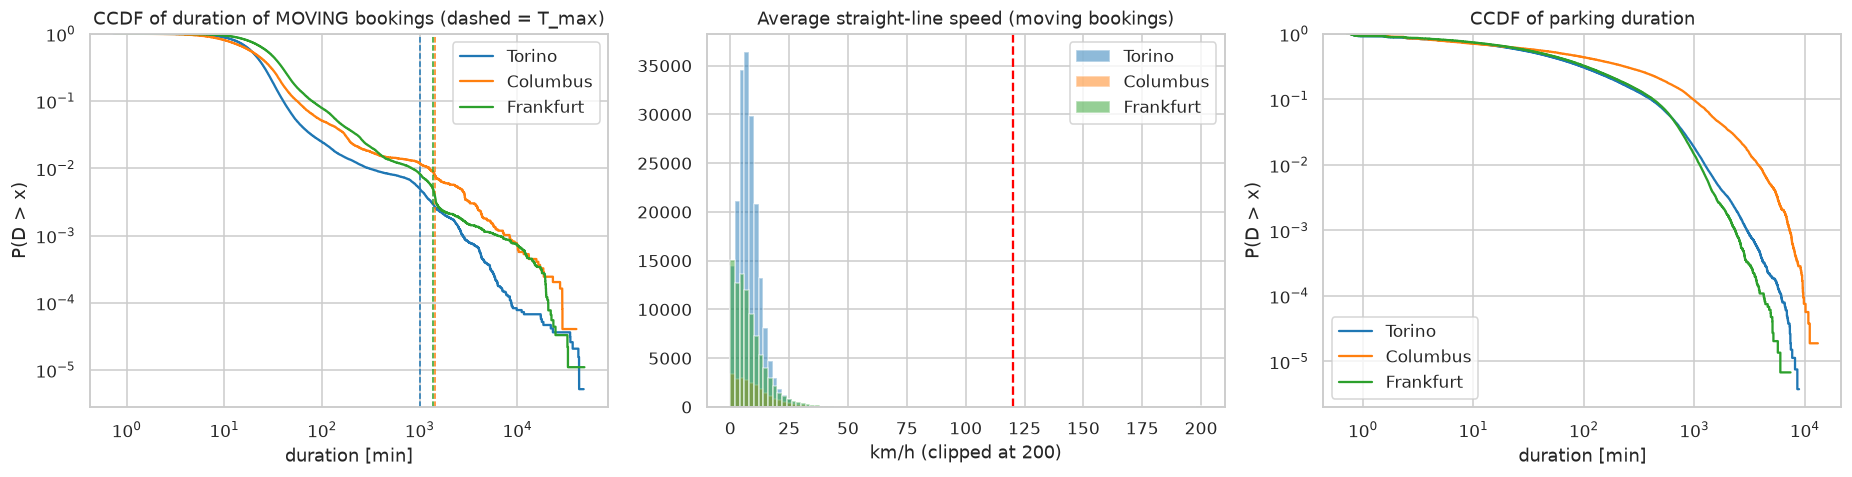

Parking max duration kept [h]: {'Torino': inf, 'Columbus': inf, 'Frankfurt': inf} | longest parking observed [days]: {'Torino': 6.2, 'Columbus': 9.1, 'Frankfurt': 5.2}


In [18]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
rows = []
for c in MY_CITIES:
    d = inp(B[c]); mv = d[d.dist_km * 1000 >= D_MIN[c]]
    T_MAX[c] = float(T_MAX_OVERRIDE.get(c, min(mv.dur_min.quantile(PARAMS["T_MAX_PCT"] / 100), PARAMS["T_MAX_CAP_MIN"])))
    sns.ecdfplot(data=mv, x="dur_min", complementary=True, log_scale=(True, True), ax=axs[0], label=c, color=PALETTE[c])
    axs[0].axvline(T_MAX[c], color=PALETTE[c], ls="--", lw=1)
    axs[1].hist(mv.speed_kmh.clip(upper=200), bins=100, alpha=.5, label=c, color=PALETTE[c])
    rows.append({"city": c, **mv.dur_min.quantile([.5, .9, .99, .995, .999]).round(1).rename(lambda q: f"p{q*100:g} [min]").to_dict(),
                 "T_max chosen [min]": round(T_MAX[c], 1), f"speed > {PARAMS['V_MAX']:.0f} km/h": int((mv.speed_kmh > PARAMS["V_MAX"]).sum())})
axs[0].set(title="CCDF of duration of MOVING bookings (dashed = T_max)", xlabel="duration [min]", ylabel="P(D > x)"); axs[0].legend()
axs[1].axvline(PARAMS["V_MAX"], color="red", ls="--"); axs[1].set(title="Average straight-line speed (moving bookings)", xlabel="km/h (clipped at 200)"); axs[1].legend()
display(pd.DataFrame(rows).set_index("city"))

for c in MY_CITIES:
    p = inp(P[c])
    P_MAX[c] = float(P_MAX_OVERRIDE.get(c, np.inf if PARAMS["P_MAX_PCT"] is None else p.dur_min.quantile(PARAMS["P_MAX_PCT"] / 100)))
    sns.ecdfplot(data=p, x="dur_min", complementary=True, log_scale=(True, True), ax=axs[2], label=c, color=PALETTE[c])
    if np.isfinite(P_MAX[c]): axs[2].axvline(P_MAX[c], color=PALETTE[c], ls="--", lw=1)
axs[2].set(title="CCDF of parking duration", xlabel="duration [min]", ylabel="P(D > x)"); axs[2].legend()
plt.tight_layout(); savefig("step2_3_duration_thresholds"); plt.show()
print("Parking max duration kept [h]:", {c: round(P_MAX[c] / 60, 1) for c in MY_CITIES}, "| longest parking observed [days]:", {c: round(inp(P[c]).dur_min.max() / 1440, 1) for c in MY_CITIES})

**Parkings** have no origin/destination, hence no independent signal such as the distance. The only artefact we can identify is the same single-snapshot glitch as for bookings (< 1 min, rule P_MIN).
We deliberately **do not cut the upper tail** of the parking durations: the CCDF decays smoothly with no break, the longest parking is only 5–9 days, and cutting e.g. the top 1 % (≈ 19–63 h) would remove genuine long parkings (nights, weekends, peripheral zones) which, being long, carry a large share of the parked *time* and would bias the occupancy downwards by ~10–15 points. Filtering is therefore *less certain* for parkings than for bookings – to be stated in the report.

In [19]:
def rental_mask(df, city):
    return ((df.dur_min >= PARAMS["T_MIN"]) & (df.dist_km * 1000 >= D_MIN[city]) &
            (df.speed_kmh <= PARAMS["V_MAX"]) & (df.dur_min <= T_MAX[city])).fillna(False)

def park_mask(df, city):
    return (df.dur_min >= PARAMS["P_MIN"]) & (df.dur_min <= P_MAX[city])

BF = {c: B[c][rental_mask(B[c], c)].copy() for c in MY_CITIES}      # filtered rentals (kept with margin for occupancy)
PF = {c: P[c][park_mask(P[c], c)].copy() for c in MY_CITIES}

wf = []
for c in MY_CITIES:
    d = inp(B[c]); n0 = len(d)
    m1 = d.dur_min >= PARAMS["T_MIN"]; m2 = m1 & (d.dist_km * 1000 >= D_MIN[c]); m3 = m2 & (d.speed_kmh <= PARAMS["V_MAX"]); m4 = m3 & (d.dur_min <= T_MAX[c])
    wf.append({"city": c, "bookings": n0, "after R1 (duration)": int(m1.sum()), "after R2 (moved)": int(m2.sum()),
               "after R3 (speed)": int(m3.sum()), "after R4 (T_max) = RENTALS": int(m4.sum()), "kept [%]": round(100 * m4.sum() / n0, 1),
               "no coordinates": int(d.dist_km.isna().sum())})
wf = pd.DataFrame(wf).set_index("city"); display(wf); wf.to_csv("tables/step2_3_filter_waterfall_bookings.csv")
pw = pd.DataFrame({c: {"parkings": len(inp(P[c])), "kept": len(inp(PF[c])), "kept [%]": round(100 * len(inp(PF[c])) / len(inp(P[c])), 1)} for c in MY_CITIES}).T
display(pw); pw.to_csv("tables/step2_3_filter_parkings.csv")

# sensitivity of the share of data kept to each threshold (the other rules stay at their chosen value)
def kept_share(c, dmin=None, tmax=None):
    d = inp(B[c]); dmin = D_MIN[c] if dmin is None else dmin; tmax = T_MAX[c] if tmax is None else tmax
    ok = (d.dur_min >= PARAMS["T_MIN"]) & (d.dist_km * 1000 >= dmin) & (d.speed_kmh <= PARAMS["V_MAX"]) & (d.dur_min <= tmax)
    return round(100 * ok.mean(), 1)
sens = pd.concat([pd.DataFrame({c: {f"d_min = {x} m": kept_share(c, dmin=x) for x in (0, 50, 100, 200, 300, 500)} for c in MY_CITIES}),
                  pd.DataFrame({c: {f"T_max = {x} min": kept_share(c, tmax=x) for x in (60, 120, 180, 360, 720, 1440)} for c in MY_CITIES})])
print("Sensitivity: % of bookings kept as rentals"); display(sens); sens.to_csv("tables/step2_3_sensitivity.csv")

,bookings,after R1 (duration),after R2 (moved),after R3 (speed),after R4 (T_max) = RENTALS,kept [%],no coordinates
city,,,,,,,
Torino,264672,240490,192540,192446,191482,72.3,0
Columbus,52885,42157,24573,24572,24383,46.1,0
Frankfurt,146591,135536,90794,90735,90280,61.6,0


,parkings,kept,kept [%]
Torino,264706.0,242033.0,91.4
Columbus,52832.0,49847.0,94.4
Frankfurt,146878.0,135628.0,92.3


Sensitivity: % of bookings kept as rentals


,Torino,Columbus,Frankfurt
d_min = 0 m,90.5,79.3,92.1
d_min = 50 m,72.3,46.1,61.6
d_min = 100 m,72.0,45.7,61.1
d_min = 200 m,71.3,44.9,60.1
d_min = 300 m,70.6,44.1,59.0
d_min = 500 m,69.1,42.6,57.1
T_max = 60 min,69.5,42.3,53.1
T_max = 120 min,71.2,44.4,57.9
T_max = 180 min,71.7,45.1,59.5
T_max = 360 min,72.0,45.7,60.8


**Reading the sensitivity table:** the share of data kept must be almost flat around the chosen values (robust threshold). `d_min`: all non-moving bookings have distance ≈ 0, none between ~0 and ~100 m, so any `d_min` in 1–100 m gives the same result (the value 50 m is simply the lower clip of the valley search); only values above ~300 m start removing real short trips.
`T_max`: beyond ~3 h the share kept changes by < 1 point, so any cap between 6 h and 24 h is equivalent for *counts*; it does matter for *mean/standard deviation* (heavy tail), which is why the median and percentiles are the main statistics in 2.5.

### 2.3b Comparison with a purely statistical filter
A common alternative is to ignore the spatial information and keep the *shortest interval of the log-duration that contains a fixed share $q$ of the bookings* (here $q = 90\%$). It removes exactly 10 % of the data in every city **by construction**, whatever the data look like.
We apply it to the same bookings and measure what it does with respect to our criterion R1–R4 and, independently, with respect to the bookings that have Google Maps data (these exist only for bookings with a real destination, hence they are almost surely real trips).

In [20]:
def best_zone(x, q=0.90):
    # shortest interval [a, b] of log(duration) containing a share q of the observations
    x = np.sort(np.asarray(x, float)); x = x[x > 0]; t = np.log(x); n = len(x); k = int(np.ceil(q * n))
    w = t[k - 1:] - t[:n - k + 1]; i = int(np.argmin(w))
    return x[i], x[i + k - 1]

rows = []
for c in MY_CITIES:
    d = inp(B[c]); a, b = best_zone(d.dur_min.values)
    stat = d.dur_min.between(a, b)                       # statistical filter
    ours = rental_mask(d, c)                             # movement-based criterion
    has_g = d.pt_min > 0                                   # bookings with Google data (almost surely real trips)
    moved = d.dist_km * 1000 >= D_MIN[c]
    rows.append({"city": c, "interval kept [min]": f"[{a:.1f}, {b:.1f}]",
                 "statistical keeps [%]": round(100 * stat.mean(), 1), "R1-R4 keeps [%]": round(100 * ours.mean(), 1),
                 "non-moving bookings inside its output [%]": round(100 * (stat & ~moved).sum() / stat.sum(), 1),
                 "R1-R4 rentals it discards [%]": round(100 * (ours & ~stat).sum() / ours.sum(), 1),
                 "Google-data bookings kept: statistical [%]": round(100 * stat[has_g].mean(), 1) if has_g.any() else np.nan,
                 "Google-data bookings kept: R1-R4 [%]": round(100 * ours[has_g].mean(), 1) if has_g.any() else np.nan,
                 "median kept: statistical / R1-R4 [min]": f"{d.dur_min[stat].median():.1f} / {d.dur_min[ours].median():.1f}"})
cmp_f = pd.DataFrame(rows).set_index("city"); display(cmp_f.T); cmp_f.to_csv("tables/step2_3b_statistical_vs_movement_filter.csv")

city,Torino,Columbus,Frankfurt
interval kept [min],"[0.8, 38.0]","[0.8, 44.0]","[0.8, 60.1]"
statistical keeps [%],90.0,90.0,90.0
R1-R4 keeps [%],72.3,46.1,61.6
non-moving bookings inside its output [%],28.3,55.7,40.9
R1-R4 rentals it discards [%],11.0,13.7,13.7
Google-data bookings kept: statistical [%],90.4,NaN,NaN
Google-data bookings kept: R1-R4 [%],99.2,NaN,NaN
median kept: statistical / R1-R4 [min],16.4 / 20.2,9.0 / 20.7,23.8 / 29.6


### 2.4 Utilisation and CDFs after filtering

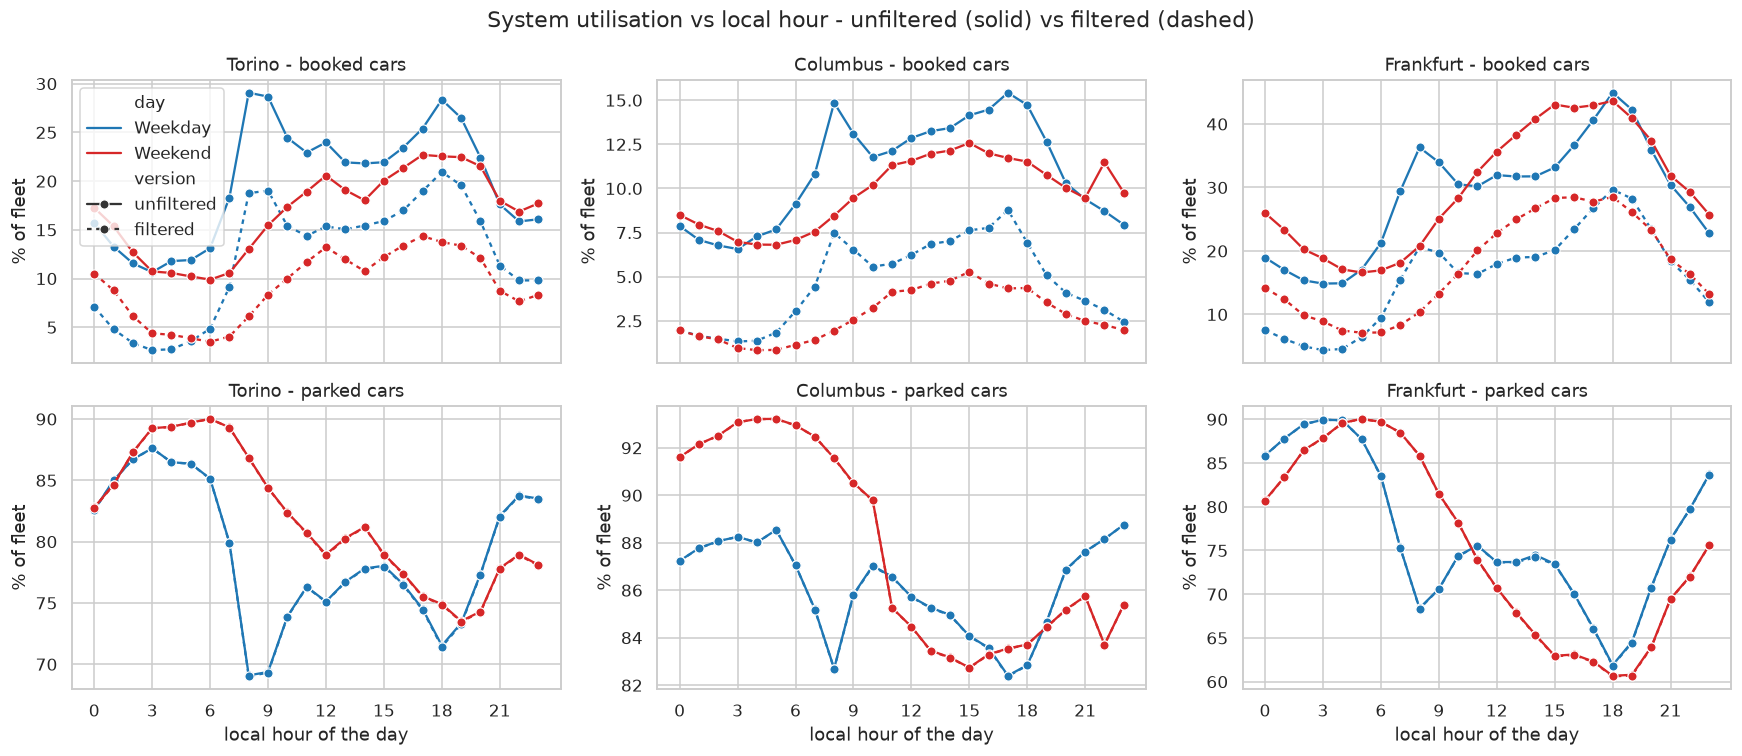

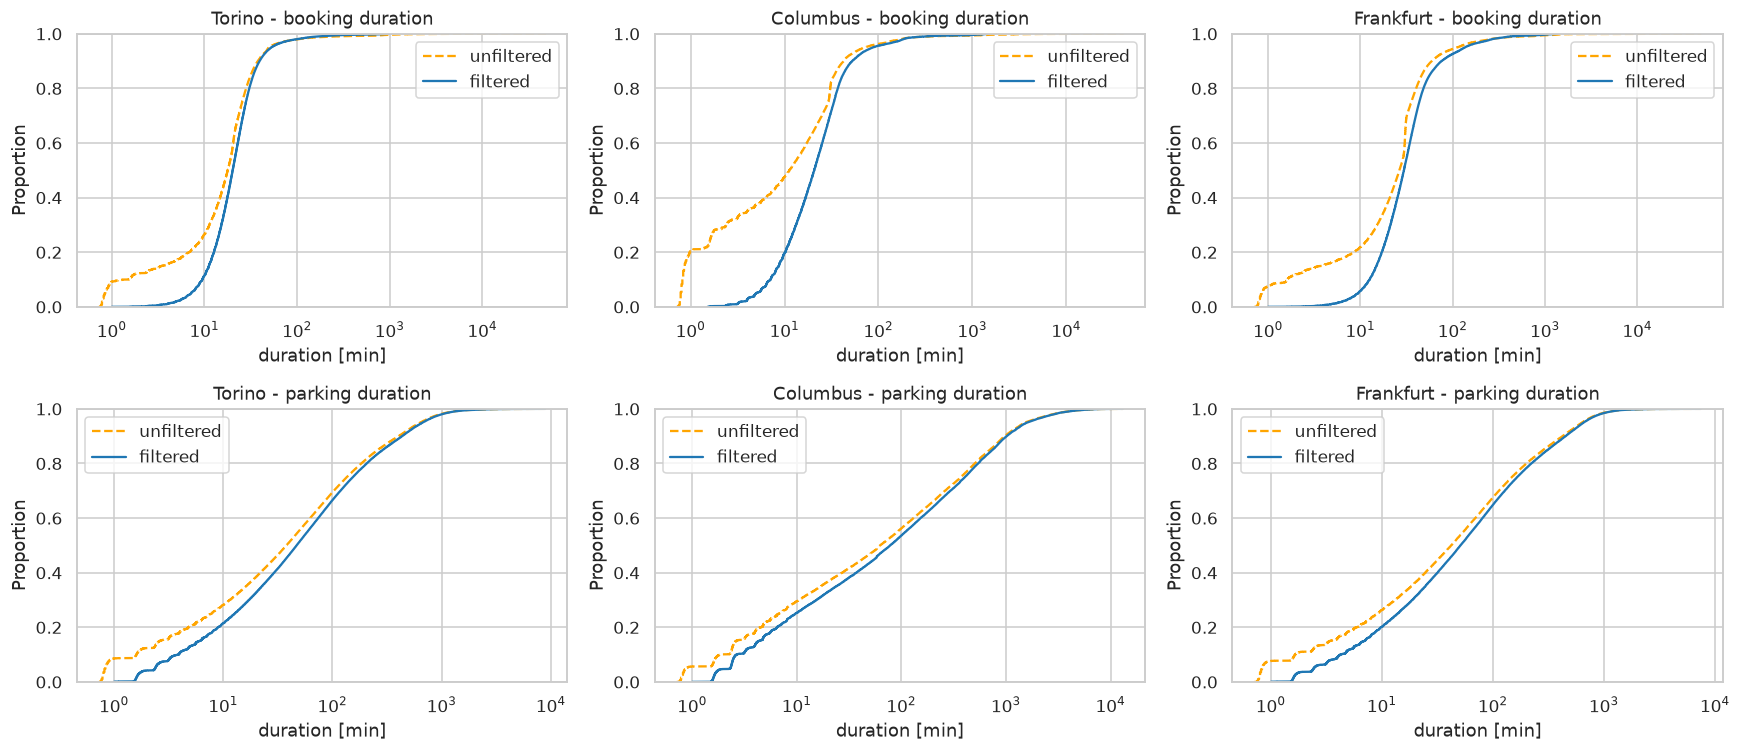

Max booked / parked percentage after filtering:


kind,booked,parked
city,,
Columbus,8.8,93.2
Frankfurt,29.7,90.0
Torino,20.9,90.0


Mean of booked% + parked% (unfiltered ~100 %; filtered < 100 %: the missing share = phantom bookings and glitches removed)


kind                  booked  parked  booked + parked
city      version                                    
Columbus  filtered       3.7    87.0             90.7
          unfiltered    10.3    87.0             97.3
Frankfurt filtered      16.8    76.2             92.9
          unfiltered    29.3    76.2            105.5
Torino    filtered      10.7    80.5             91.2
          unfiltered    18.3    80.5             98.9

In [21]:
prof_flt = profiles(BF, PF, "filtered")
plot_profiles(pd.concat([prof_raw, prof_flt]), "System utilisation vs local hour - unfiltered (solid) vs filtered (dashed)", "step2_4_utilisation_comparison")

fig, axs = plt.subplots(2, len(MY_CITIES), figsize=(16, 7))
for k, c in enumerate(MY_CITIES):
    for r, (raw, flt, nm) in enumerate(((B, BF, "booking"), (P, PF, "parking"))):
        sns.ecdfplot(data=inp(raw[c]), x="dur_min", log_scale=True, ax=axs[r, k], color="orange", ls="--", label="unfiltered")
        sns.ecdfplot(data=inp(flt[c]), x="dur_min", log_scale=True, ax=axs[r, k], color="tab:blue", label="filtered")
        axs[r, k].set(title=f"{c} - {nm} duration", xlabel="duration [min]"); axs[r, k].legend()
plt.tight_layout(); savefig("step2_4_cdf_filtered_vs_unfiltered"); plt.show()
print("Max booked / parked percentage after filtering:"); display(prof_flt.groupby(["city", "kind"]).pct.max().unstack().round(1))
# sanity check: every car is either booked or parked, so booked% + parked% should be ~100 % when unfiltered
chk = pd.concat([prof_raw, prof_flt]).pivot_table(index=["city", "version", "day", "hour"], columns="kind", values="pct")
chk["booked + parked"] = chk.booked + chk.parked
print("Mean of booked% + parked% (unfiltered ~100 %; filtered < 100 %: the missing share = phantom bookings and glitches removed)")
display(chk.groupby(["city", "version"])[["booked", "parked", "booked + parked"]].mean().round(1))
chk.groupby(["city", "version"])[["booked", "parked", "booked + parked"]].mean().round(1).to_csv("tables/step2_4_state_balance.csv")

### 2.5 Daily statistics of rental / parking duration (filtered data, per city)
Mean, median, standard deviation and percentiles (25/75/90) per local day. Weekends are shaded and public holidays marked.
Periodicity is quantified with the weekday profile, the weekend/weekday ratio and the autocorrelation at lag 7; the trend with a linear regression and the comparison of the three months and of the Christmas period.
The last, incomplete day (31 Jan) and outage days are excluded.

Torino     holidays in the period: ['2017-11-01', '2017-11-05', '2017-12-08', '2017-12-25', '2017-12-26', '2018-01-01', '2018-01-06']
Columbus   holidays in the period: ['2017-11-10', '2017-11-11', '2017-11-23', '2017-12-25', '2018-01-01', '2018-01-15']
Frankfurt  holidays in the period: ['2017-12-25', '2017-12-26', '2018-01-01']


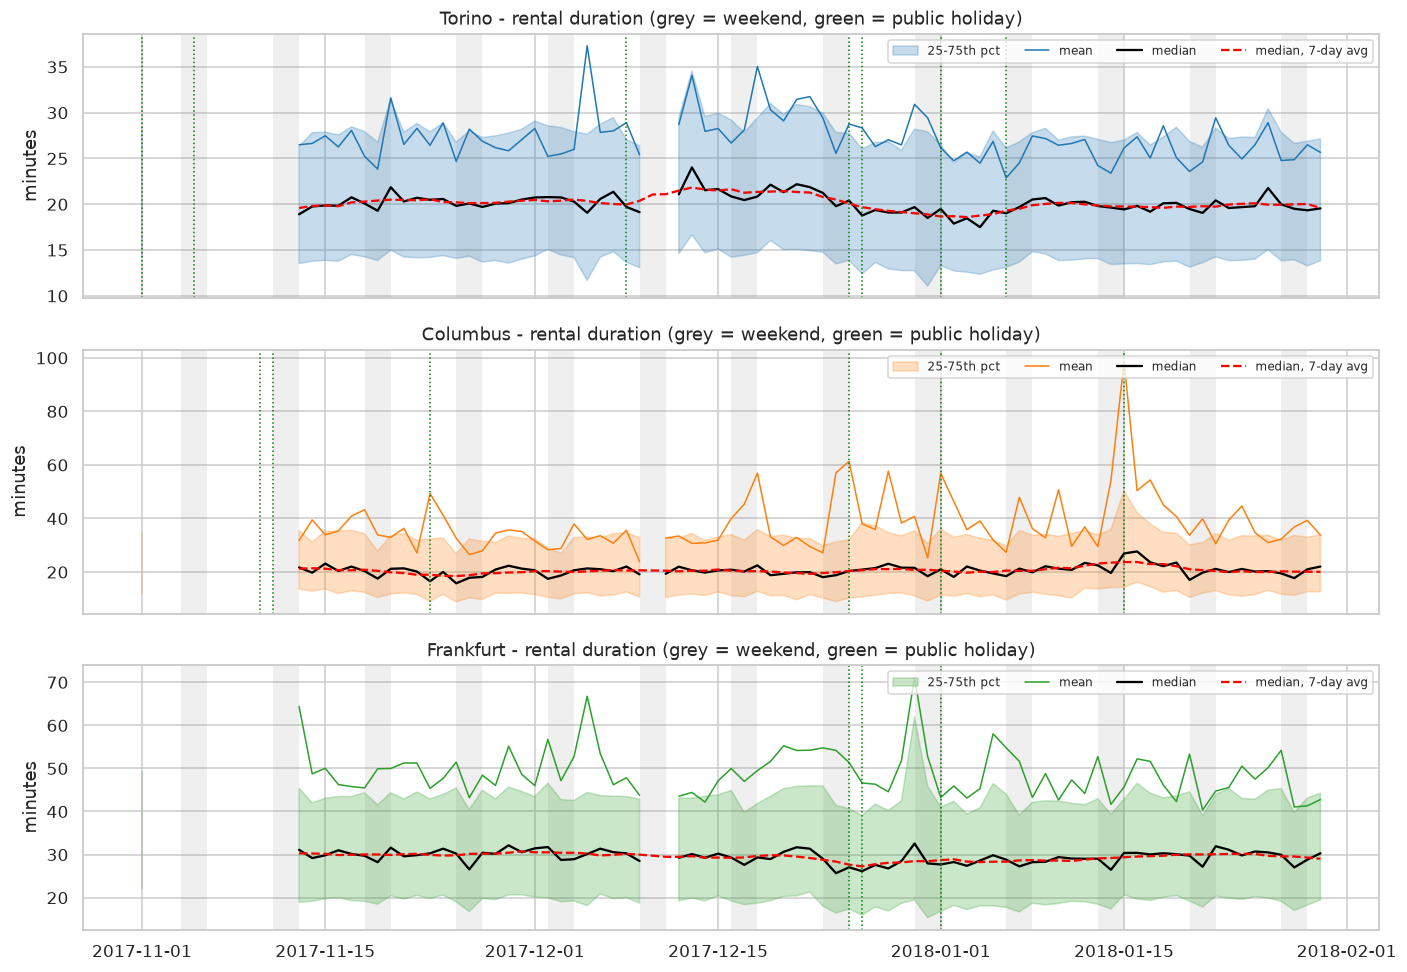

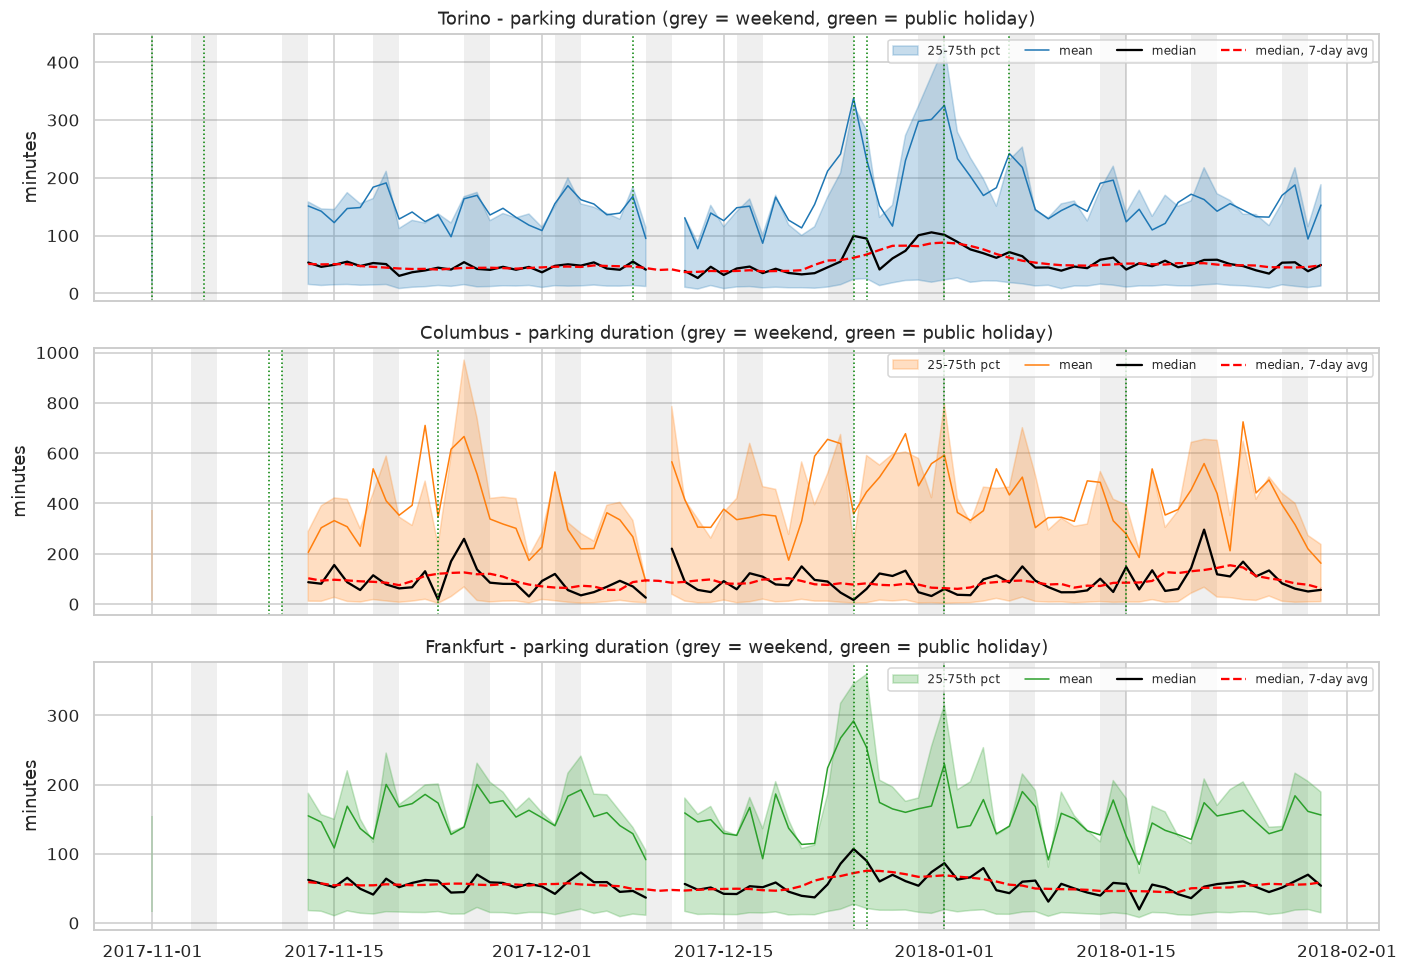

,kind,weekend/weekday (median of medians),autocorr lag 7,trend [min/day],trend p-value,Nov,Dec,Jan,Christmas period / rest
city,,,,,,,,,
Torino,rentals,0.98,0.16,-0.0101,0.039,20.2,20.6,19.6,0.94
Columbus,rentals,0.90,0.08,0.0166,0.077,20.1,20.3,21.1,0.99
Frankfurt,rentals,0.96,0.39,-0.0174,0.020,30.3,29.3,29.2,0.94
Torino,parkings,1.15,0.27,0.1141,0.163,46.8,51.8,54.8,1.66
Columbus,parkings,1.19,-0.02,0.0828,0.733,97.8,82.1,94.2,0.83
Frankfurt,parkings,0.96,0.39,-0.0181,0.782,55.5,57.0,53.4,1.33


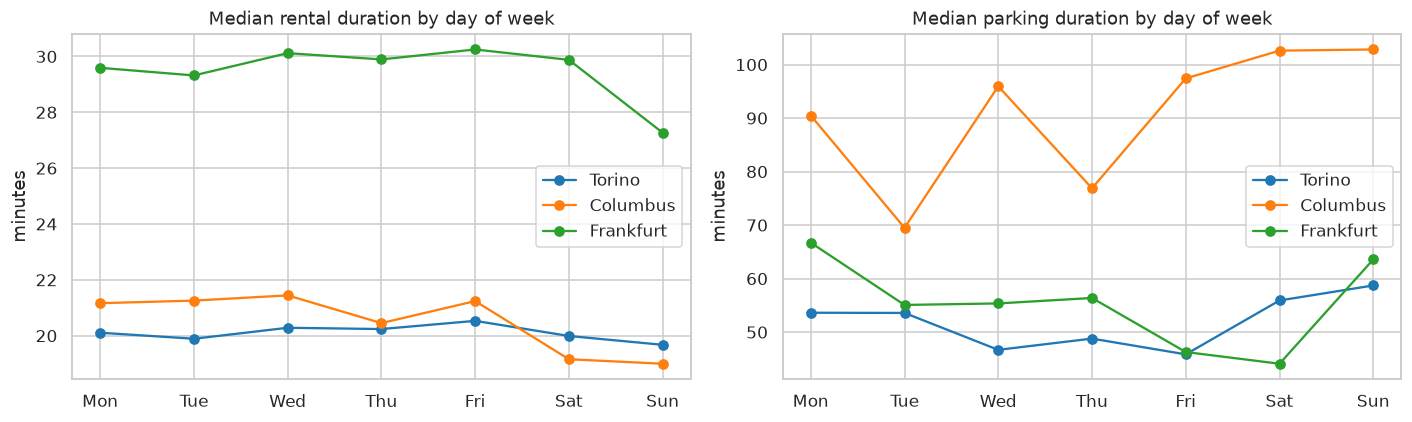

In [22]:
# public holidays: from the `holidays` package (Torino = IT/TO, Frankfurt = DE/HE, Columbus = US/OH); fallback to a manual list
HOLIDAYS_MANUAL = {"Torino": ["2017-11-01", "2017-12-08", "2017-12-25", "2017-12-26", "2018-01-01", "2018-01-06"],
                   "Frankfurt": ["2017-12-25", "2017-12-26", "2018-01-01"],
                   "Columbus": ["2017-11-23", "2017-12-25", "2018-01-01"]}
try:
    import holidays as hol
    CAL = {"Torino": ("IT", "TO"), "Frankfurt": ("DE", "HE"), "Columbus": ("US", "OH")}
    HOLIDAYS = {}
    for c, (country, sub) in CAL.items():
        cal = hol.country_holidays(country, subdiv=sub, years=[2017, 2018])
        HOLIDAYS[c] = sorted(pd.Timestamp(d).strftime("%Y-%m-%d") for d in cal
                             if pd.Timestamp(PERIOD[0]) <= pd.Timestamp(d) < pd.Timestamp(PERIOD[1]))
except Exception as e:
    print("`holidays` package not usable (", type(e).__name__, ") -> manual list")
    HOLIDAYS = HOLIDAYS_MANUAL
for c in MY_CITIES: print(f"{c:10s} holidays in the period:", HOLIDAYS[c])
XMAS = (pd.Timestamp("2017-12-23"), pd.Timestamp("2018-01-07"))

def daily_table(df, city):
    g = df.groupby("date")["dur_min"]
    t = pd.DataFrame({"n": g.size(), "mean": g.mean(), "median": g.median(), "std": g.std(),
                      "p25": g.quantile(.25), "p75": g.quantile(.75), "p90": g.quantile(.90)})
    t = t.reindex(pd.date_range(PERIOD[0], LAST_FULL_DAY)).rename_axis("date")
    t.loc[t.index.isin(OUTAGE[city])] = np.nan
    return t

def plot_daily(frames, kind, ylabel, fname):
    fig, axs = plt.subplots(len(MY_CITIES), 1, figsize=(13, 9), sharex=True)
    for ax, c in zip(axs, MY_CITIES):
        t = frames[c]
        for day in t.index[t.index.dayofweek == 5]:
            ax.axvspan(day, day + pd.Timedelta(days=2), color="grey", alpha=.12, lw=0)
        ax.fill_between(t.index, t.p25, t.p75, alpha=.25, color=PALETTE[c], label="25-75th pct")
        ax.plot(t.index, t["mean"], color=PALETTE[c], lw=1, label="mean")
        ax.plot(t.index, t["median"], color="black", lw=1.5, label="median")
        ax.plot(t.index, t["median"].rolling(7, center=True, min_periods=4).mean(), color="red", ls="--", label="median, 7-day avg")
        for h in HOLIDAYS[c]: ax.axvline(pd.Timestamp(h), color="green", ls=":", lw=1)
        ax.set(ylabel=ylabel, title=f"{c} - {kind} (grey = weekend, green = public holiday)"); ax.legend(loc="upper right", ncol=4, fontsize=8)
    plt.tight_layout(); savefig(fname); plt.show()

DB_ = {c: daily_table(inp(BF[c]), c) for c in MY_CITIES}
DP_ = {c: daily_table(inp(PF[c]), c) for c in MY_CITIES}
plot_daily(DB_, "rental duration", "minutes", "step2_5_daily_rentals")
plot_daily(DP_, "parking duration", "minutes", "step2_5_daily_parkings")

def periodicity_report(frames, kind):
    rows = []
    for c, t in frames.items():
        m = t["median"].dropna(); wd = t.groupby(t.index.dayofweek)["median"].mean()
        x = (m.index - m.index[0]).days.values; lr = stats.linregress(x, m.values)
        xm = t.loc[(t.index >= XMAS[0]) & (t.index <= XMAS[1]), "median"].mean(); rest = t.loc[(t.index < XMAS[0]) | (t.index > XMAS[1]), "median"].mean()
        rows.append({"city": c, "kind": kind, "weekend/weekday (median of medians)": round(wd.loc[[5, 6]].mean() / wd.loc[0:4].mean(), 2),
                     "autocorr lag 7": round(m.autocorr(7), 2), "trend [min/day]": round(lr.slope, 4), "trend p-value": round(lr.pvalue, 3),
                     "Nov": round(t.loc["2017-11", "median"].mean(), 1), "Dec": round(t.loc["2017-12", "median"].mean(), 1), "Jan": round(t.loc["2018-01", "median"].mean(), 1),
                     "Christmas period / rest": round(xm / rest, 2)})
    return pd.DataFrame(rows).set_index("city")
# NB: the trend p-values assume independent daily values; with autocorrelation (lag 7) they are optimistic -> read them as indicative only
per = pd.concat([periodicity_report(DB_, "rentals"), periodicity_report(DP_, "parkings")]); display(per); per.to_csv("tables/step2_5_periodicity.csv")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, fr, nm in zip(axs, (DB_, DP_), ("rental", "parking")):
    for c in MY_CITIES:
        wd = fr[c].groupby(fr[c].index.dayofweek)["median"].mean(); ax.plot(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], wd.values, marker="o", color=PALETTE[c], label=c)
    ax.set(title=f"Median {nm} duration by day of week", ylabel="minutes"); ax.legend()
plt.tight_layout(); savefig("step2_5_weekday_profile"); plt.show()
pd.concat({c: DB_[c] for c in MY_CITIES}).to_csv("tables/step2_5_daily_rentals.csv")
pd.concat({c: DP_[c] for c in MY_CITIES}).to_csv("tables/step2_5_daily_parkings.csv")

### 2.6 Probability of a rental vs the alternative transport option (City 1: Torino, public transport)
**(a)** We keep the valid rentals (section 2.3) that also have public-transport (PT) data from Google Maps (travel time, in seconds in the DB → minutes; `-1` = not available).

**(b) What does the histogram measure?** Counting the rentals in each PT-duration bin gives
$P(x \mid \text{rental})$: *given* a rental, how likely is its PT alternative to last $x$ minutes. The question is instead
$P(\text{rental} \mid x) = P(x\mid\text{rental})\,P(\text{rental}) / P(x)$:
the denominator $P(x)$ is the distribution of PT times of **all possible trips** in the city, which is not observed. We therefore present
1. the histogram $P(x\mid\text{rental})$ (what is directly observed), together with the ratio PT time / driving time of the same trip;
2. an estimate of the *relative propensity* $P(x\mid\text{rental})/P(x)$, where $P(x)$ is approximated by Monte-Carlo: random origin–destination pairs drawn from the points where rentals start/end, with PT time resampled from observed rentals with similar straight-line distance. Only the *shape* of this ratio is meaningful (it is defined up to the constant $P(\text{rental})$), and it depends on the assumption that potential trips are uniformly spread over the visited points – to be stated as a limitation in the report.

*Note on bookings as denominator:* Google data exist almost only for bookings that are real trips, so "rentals / bookings in each bin" would be ≈ 100 % in every bin and carries no information; we only use this fact as an independent **validation of the rental filter** (printed below).

Torino: valid rentals = 191,482; with PT data = 62,724 (32.8 % of the rentals); bookings with PT data = 63,242
Validation of the filter: 99.2 % of the bookings that have PT data are classified as valid rentals, versus 72.3 % of all bookings


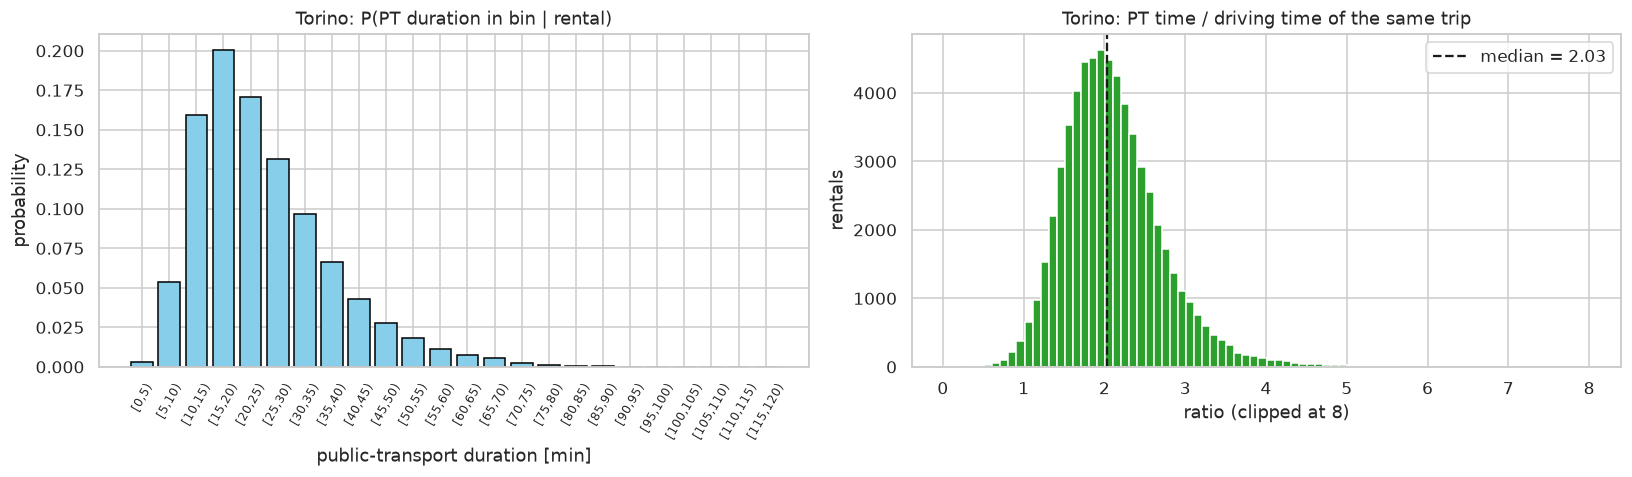

PT duration of rentals: median = 22.3 min, mean = 24.9 min; rental duration: median = 19.9 min


In [23]:
BIN = 5; EDGES = np.arange(0, 125, BIN)
R = inp(BF[CITY1]); Rpt = R[R.pt_min.between(0.1, 120)].copy()
Ball = inp(B[CITY1]); Bpt = Ball[Ball.pt_min.between(0.1, 120)].copy()
print(f"{CITY1}: valid rentals = {len(R):,}; with PT data = {len(Rpt):,} ({100*len(Rpt)/len(R):.1f} % of the rentals); bookings with PT data = {len(Bpt):,}")
print(f"Validation of the filter: {100*len(Rpt)/len(Bpt):.1f} % of the bookings that have PT data are classified as valid rentals, versus {100*len(R)/len(Ball):.1f} % of all bookings")

lab = lambda e: [f"[{a},{a+BIN})" for a in e[:-1]]
Rpt["bin"] = pd.cut(Rpt.pt_min, EDGES, right=False, labels=lab(EDGES))
cnt_r = Rpt.bin.value_counts().reindex(lab(EDGES)).fillna(0)
p_x_given_rental = cnt_r / cnt_r.sum()
ratio = (Rpt.pt_min / Rpt.drive_min.where(Rpt.drive_min > 0)).replace([np.inf, -np.inf], np.nan).dropna()      # PT time / Google driving time of the same trip

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].bar(range(len(cnt_r)), p_x_given_rental.values, color="skyblue", edgecolor="black")
axs[0].set(title=f"{CITY1}: P(PT duration in bin | rental)", xlabel="public-transport duration [min]", ylabel="probability")
axs[0].set_xticks(range(len(cnt_r))); axs[0].set_xticklabels(lab(EDGES), rotation=60, fontsize=8)
axs[1].hist(ratio.clip(upper=8), bins=80, color="tab:green")
axs[1].axvline(ratio.median(), color="k", ls="--", label=f"median = {ratio.median():.2f}")
axs[1].set(title=f"{CITY1}: PT time / driving time of the same trip", xlabel="ratio (clipped at 8)", ylabel="rentals"); axs[1].legend()
plt.tight_layout(); savefig("step2_6_pt_hist_ratio"); plt.show()
print(f"PT duration of rentals: median = {Rpt.pt_min.median():.1f} min, mean = {Rpt.pt_min.mean():.1f} min; rental duration: median = {Rpt.dur_min.median():.1f} min")

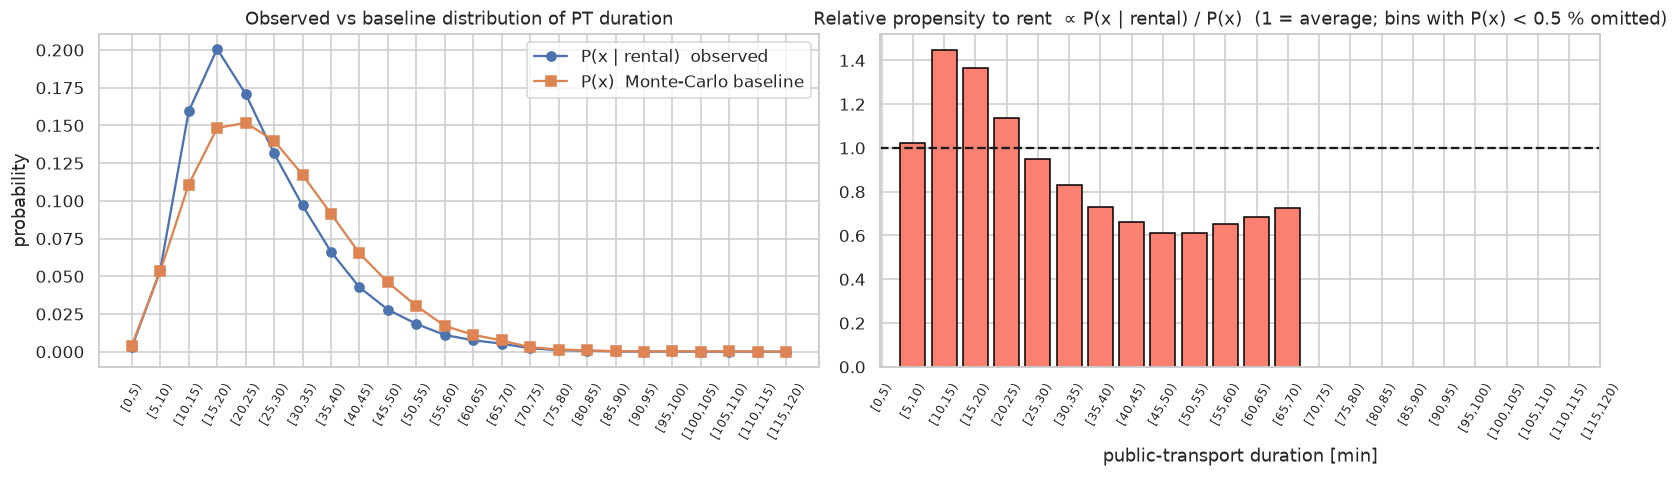

In [24]:
# (c) relative propensity P(x | rental) / P(x), with P(x) estimated by Monte Carlo
rng = np.random.default_rng(42)
Rc = R.dropna(subset=["lat0", "lon0", "lat1", "lon1"])
pts = np.vstack([Rc[["lat0", "lon0"]].values, Rc[["lat1", "lon1"]].values])
N = 300_000
i, j = rng.integers(0, len(pts), N), rng.integers(0, len(pts), N)
dkm = haversine_km(pts[i, 0], pts[i, 1], pts[j, 0], pts[j, 1])

qs = np.unique(np.quantile(Rpt.dist_km, np.linspace(0, 1, 41)))                  # 40 distance bins (equal counts)
b_obs = np.clip(np.searchsorted(qs, Rpt.dist_km.values, side="right") - 1, 0, len(qs) - 2)
b_pair = np.clip(np.searchsorted(qs, dkm, side="right") - 1, 0, len(qs) - 2)
inside = (dkm >= qs[0]) & (dkm <= qs[-1])                                         # no extrapolation outside observed distances
x_pair = np.full(N, np.nan); vals = Rpt.pt_min.values
for b in range(len(qs) - 1):
    io, ip = np.where(b_obs == b)[0], np.where((b_pair == b) & inside)[0]
    if len(io) and len(ip): x_pair[ip] = vals[rng.choice(io, len(ip))]
x_pair = x_pair[~np.isnan(x_pair)]

p_base = pd.Series(np.histogram(x_pair, bins=EDGES)[0], index=lab(EDGES)); p_base = p_base / p_base.sum()
prop = (p_x_given_rental / p_base).where(p_base >= 0.005)
prop = prop / np.nansum((prop * p_base).values)                                    # 1 = average propensity

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].plot(range(len(p_base)), p_x_given_rental.values, marker="o", label="P(x | rental)  observed")
axs[0].plot(range(len(p_base)), p_base.values, marker="s", label="P(x)  Monte-Carlo baseline"); axs[0].legend()
axs[0].set(title="Observed vs baseline distribution of PT duration", ylabel="probability")
axs[1].bar(range(len(prop)), prop.values, color="salmon", edgecolor="black"); axs[1].axhline(1, color="k", ls="--")
axs[1].set(title="Relative propensity to rent  ∝ P(x | rental) / P(x)  (1 = average; bins with P(x) < 0.5 % omitted)", xlabel="public-transport duration [min]")
for ax in axs: ax.set_xticks(range(len(prop))); ax.set_xticklabels(lab(EDGES), rotation=60, fontsize=8)
plt.tight_layout(); savefig("step2_6_pt_propensity"); plt.show()
pd.DataFrame({"P(x|rental)": p_x_given_rental, "rentals": cnt_r, "P(x) MC": p_base, "propensity": prop}).to_csv("tables/step2_6_pt_bins.csv")

### 2.7 Spatial analysis of rentals (City 1: Torino)
Valid rentals only. Origins are placed at the **start** time, destinations at the **end** time of each rental (local time).
The city is divided in a regular grid of 500 m × 500 m cells (cropped to the area where rentals actually occur); for each time window we compute **trip generation** (rentals starting in each cell) and **trip attraction** (rentals ending in each cell), normalised by the number of days of that type in the period (average trips per day), plus the net flow (attraction − generation).
Collection-gap days **and public holidays** are excluded from these windows (e.g. 25 Dec and 1 Jan are Mondays but not typical Mondays).
Windows compared: Monday 8–10 vs Monday 18–20 (same day, different time); Monday vs Thursday 8–10 (different weekday); weekdays vs weekend 8–10.

189,950 rentals with both endpoints inside the study area; grid = 39 x 19 cells of 500 m


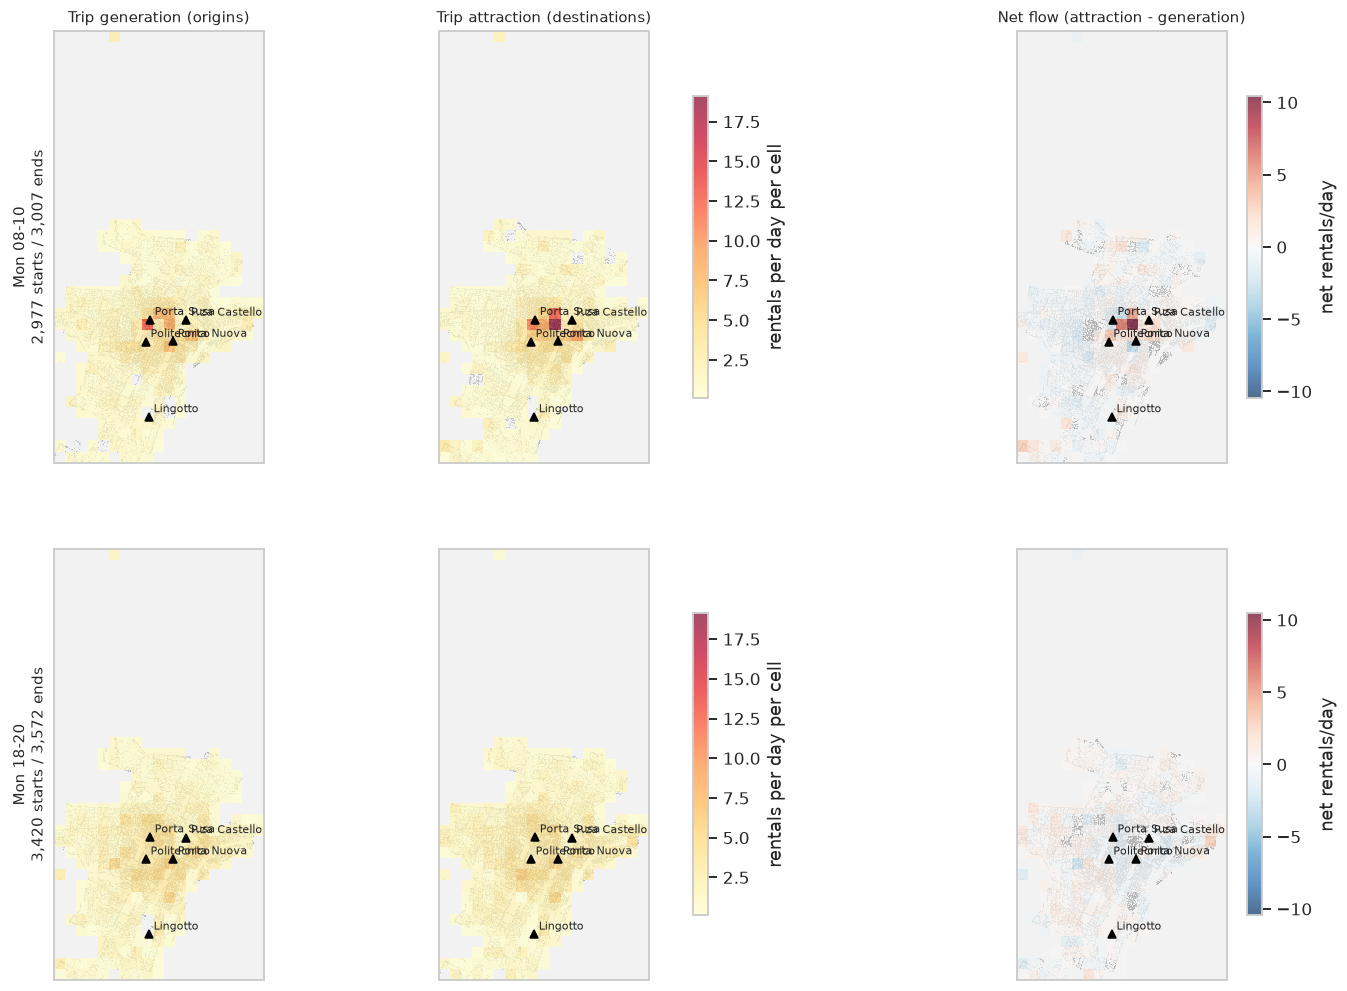

Pearson correlation between the origin maps of the windows: 0.779 | destination maps: 0.654


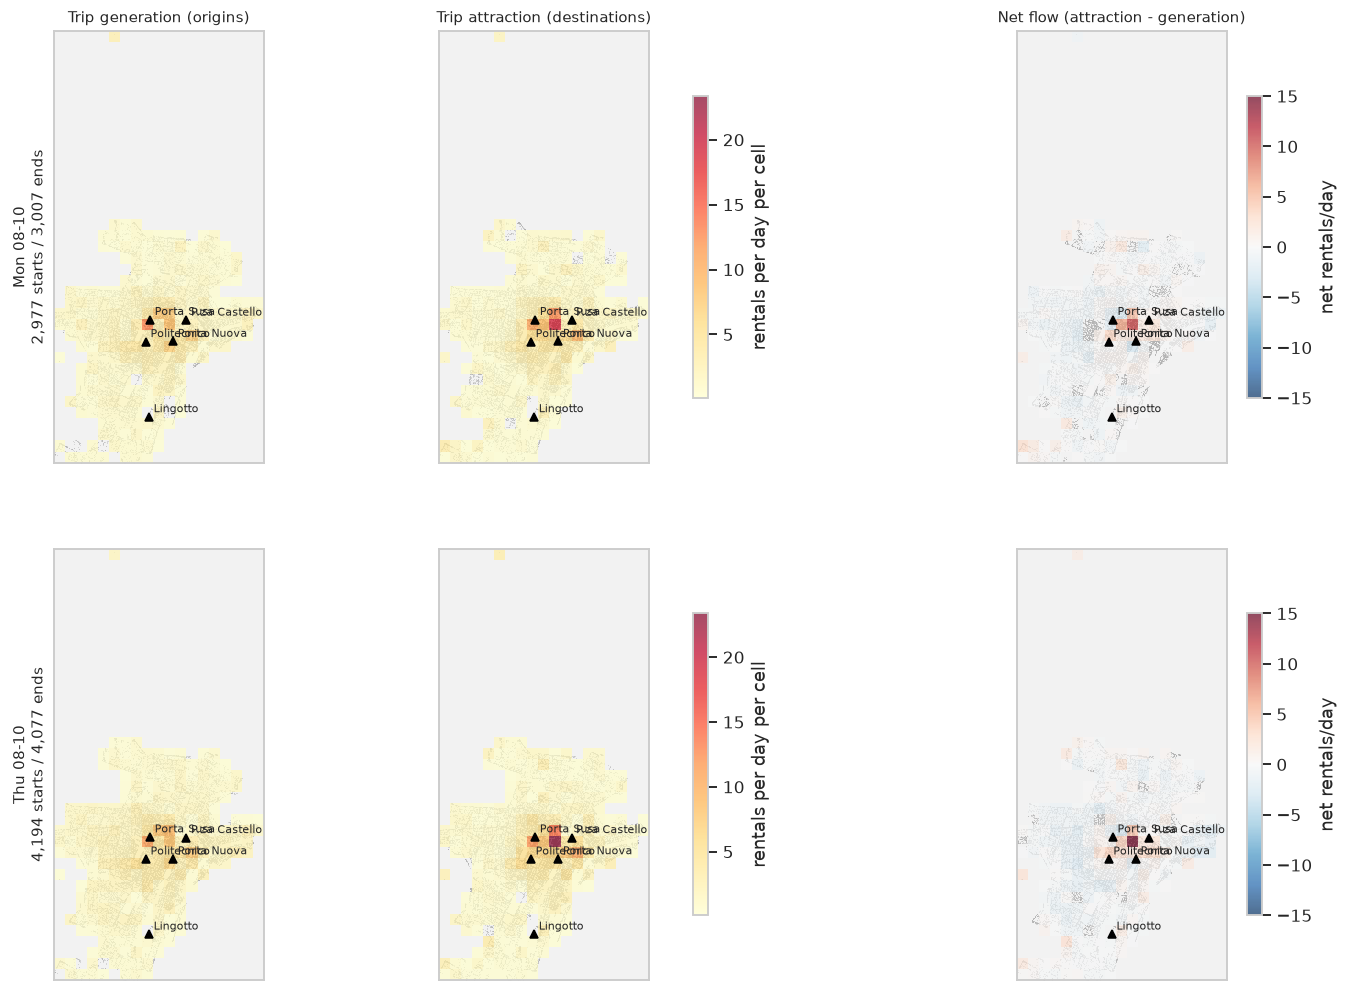

Pearson correlation between the origin maps of the windows: 0.958 | destination maps: 0.98


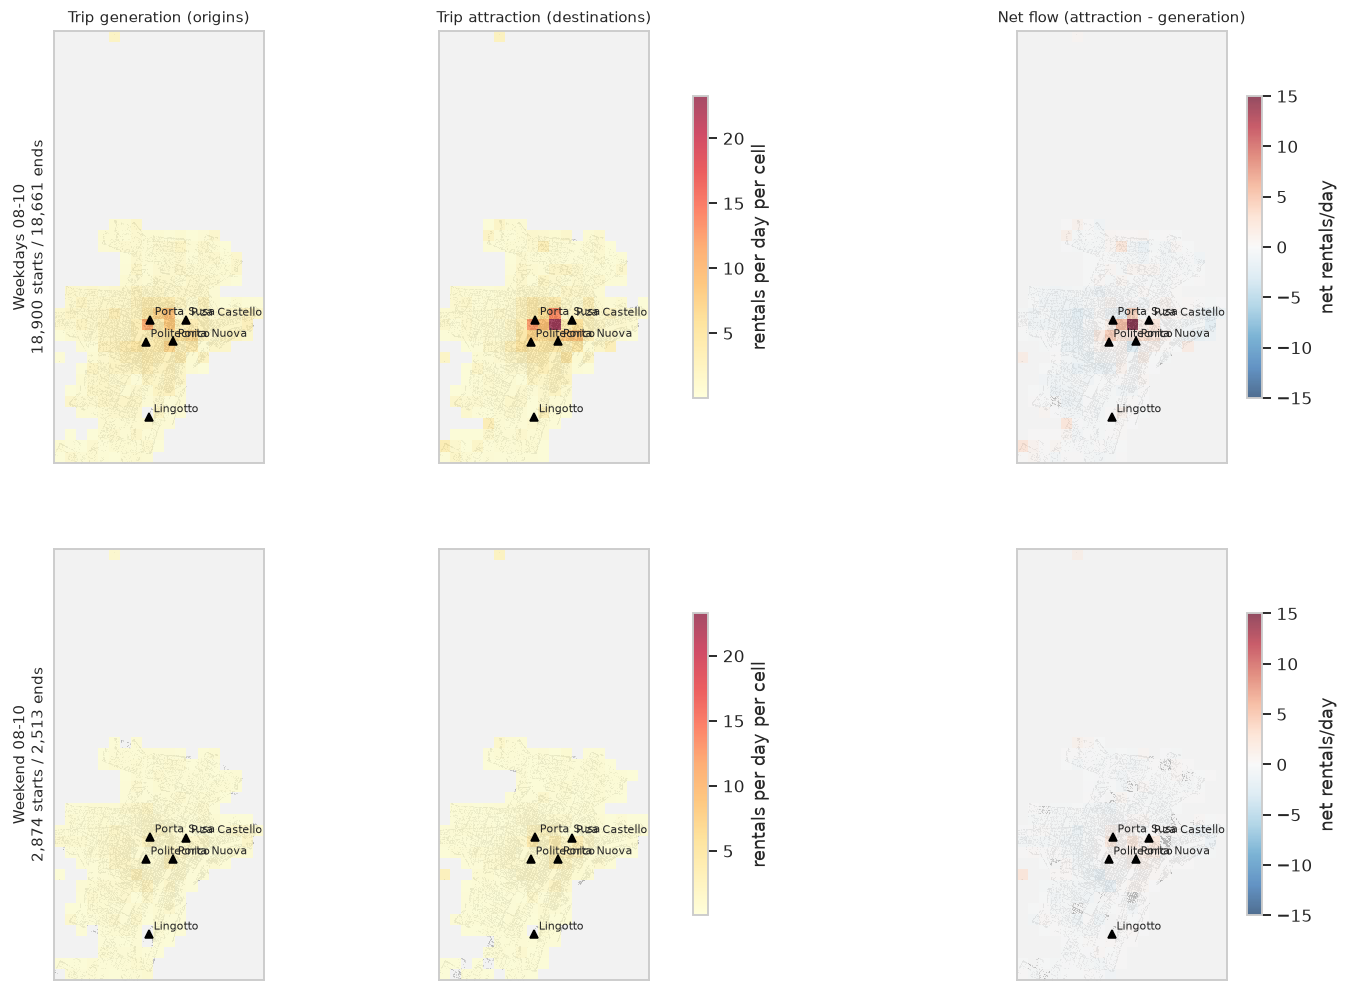

Pearson correlation between the origin maps of the windows: 0.821 | destination maps: 0.802


In [25]:
BASEMAP = "NONE"       # "NONE" (default, no external service) or "ESRI" (grey canvas, may work from your network).
                       # NB: OpenStreetMap's tile servers block automated requests (403 "Access blocked") and Carto now needs an API key.
PROVIDERS = {}
try:
    import contextily as cx
    try: PROVIDERS["ESRI"] = cx.providers.Esri.WorldGrayCanvas
    except Exception: pass
except Exception:
    cx = None

def add_basemap(ax):
    if BASEMAP == "NONE" or cx is None or BASEMAP not in PROVIDERS:
        ax.set_facecolor("#f2f2f2")
        ax.scatter(CTX[:, 1], CTX[:, 0], s=0.4, c="0.7", alpha=.35, linewidths=0, zorder=0)   # faint cloud of all rental endpoints = shape of the city
        return
    try: cx.add_basemap(ax, crs="EPSG:4326", source=PROVIDERS[BASEMAP], zoom=13, attribution=False)
    except Exception as e: print("basemap not available:", type(e).__name__)

Rs = inp(BF[CITY1]).dropna(subset=["lat0", "lon0", "lat1", "lon1"]).copy()
endl = pd.to_datetime(Rs.t1, unit="s", utc=True).dt.tz_convert(TZ[CITY1]).dt.tz_localize(None)
Rs["end_hour"], Rs["end_dow"], Rs["end_date"] = endl.dt.hour, endl.dt.dayofweek, endl.dt.normalize()

# wide grid -> keep only the area where there is real activity (cells with >= 20 events in the whole period)
allpts = np.vstack([Rs[["lat0", "lon0"]].values, Rs[["lat1", "lon1"]].values])
w0, w1 = np.quantile(allpts[:, 0], [.002, .998]); v0, v1 = np.quantile(allpts[:, 1], [.002, .998])
CELL_M = 500; latc = (w0 + w1) / 2
dlat = CELL_M / 111_320; dlon = CELL_M / (111_320 * np.cos(np.radians(latc)))
LAT_E, LON_E = np.arange(w0, w1 + dlat, dlat), np.arange(v0, v1 + dlon, dlon)
Hall = np.histogram2d(allpts[:, 0], allpts[:, 1], bins=[LAT_E, LON_E])[0]
ri, ci = np.where(Hall >= 20)
LAT_E, LON_E = LAT_E[ri.min(): ri.max() + 2], LON_E[ci.min(): ci.max() + 2]
LAT0, LAT1, LON0, LON1 = LAT_E[0], LAT_E[-1], LON_E[0], LON_E[-1]; latc = (LAT0 + LAT1) / 2
Rs = Rs[Rs.lat0.between(LAT0, LAT1) & Rs.lat1.between(LAT0, LAT1) & Rs.lon0.between(LON0, LON1) & Rs.lon1.between(LON0, LON1)]
CTX = np.vstack([Rs[["lat0", "lon0"]].values, Rs[["lat1", "lon1"]].values]); CTX = CTX[np.random.default_rng(0).choice(len(CTX), min(len(CTX), 40000), replace=False)]
print(f"{len(Rs):,} rentals with both endpoints inside the study area; grid = {len(LAT_E)-1} x {len(LON_E)-1} cells of {CELL_M} m")

SKIP = list(set(OUTAGE[CITY1]) | set(pd.to_datetime(HOLIDAYS[CITY1])))          # gap days + public holidays
ALL_DAYS = pd.date_range(PERIOD[0], LAST_FULL_DAY); ALL_DAYS = ALL_DAYS[~ALL_DAYS.isin(SKIP)]
n_days = lambda dows: int(ALL_DAYS.dayofweek.isin(dows).sum())

def window(dows, h0, h1):
    o = Rs[Rs.dow.isin(dows) & Rs.hour.between(h0, h1 - 1) & ~Rs.date.isin(SKIP)]
    d = Rs[Rs.end_dow.isin(dows) & Rs.end_hour.between(h0, h1 - 1) & ~Rs.end_date.isin(SKIP)]
    nd = max(n_days(dows), 1)
    Ho = np.histogram2d(o.lat0, o.lon0, bins=[LAT_E, LON_E])[0] / nd
    Hd = np.histogram2d(d.lat1, d.lon1, bins=[LAT_E, LON_E])[0] / nd
    return Ho, Hd, o, d

# approximate landmark coordinates (lat, lon) used only to orient the reader on the maps - check them before publishing
LANDMARKS = {"Porta Susa": (45.0714, 7.6650), "Porta Nuova": (45.0625, 7.6783), "P.za Castello": (45.0711, 7.6859),
             "Politecnico": (45.0624, 7.6626), "Lingotto": (45.0319, 7.6644)}

def mark_landmarks(ax):
    for name, (la, lo) in LANDMARKS.items():
        if LAT0 <= la <= LAT1 and LON0 <= lo <= LON1:
            ax.plot(lo, la, marker="^", ms=5, color="black", zorder=5)
            ax.annotate(name, (lo, la), xytext=(3, 3), textcoords="offset points", fontsize=7, zorder=5)

def draw(ax, H, title, cmap="YlOrRd", norm=None, vmax=None):
    Hm = np.where(H == 0, np.nan, H)
    ax.set_xlim(LON0, LON1); ax.set_ylim(LAT0, LAT1); ax.set_aspect(1 / np.cos(np.radians(latc)))
    add_basemap(ax)
    m = ax.pcolormesh(LON_E, LAT_E, Hm, cmap=cmap, norm=norm, vmax=vmax if norm is None else None, alpha=.7)
    mark_landmarks(ax)
    ax.set_xlim(LON0, LON1); ax.set_ylim(LAT0, LAT1)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); return m

def compare(windows, fname):
    res = [window(*w[1:]) for w in windows]
    vmax = max(max(h[0].max(), h[1].max()) for h in res)
    dmax = max(np.abs(h[1] - h[0]).max() for h in res)
    fig, axs = plt.subplots(len(windows), 3, figsize=(16, 5.6 * len(windows)))
    for r, (w, (Ho, Hd, o, d)) in enumerate(zip(windows, res)):
        m1 = draw(axs[r, 0], Ho, "Trip generation (origins)" if r == 0 else "", vmax=vmax)
        draw(axs[r, 1], Hd, "Trip attraction (destinations)" if r == 0 else "", vmax=vmax)
        m3 = draw(axs[r, 2], Hd - Ho, "Net flow (attraction - generation)" if r == 0 else "", cmap="RdBu_r", norm=plt.matplotlib.colors.TwoSlopeNorm(0, -dmax, dmax))
        axs[r, 0].set_ylabel(f"{w[0]}\n{len(o):,} starts / {len(d):,} ends", fontsize=10)
        fig.colorbar(m1, ax=axs[r, :2], shrink=.7, label="rentals per day per cell"); fig.colorbar(m3, ax=axs[r, 2], shrink=.7, label="net rentals/day")
    savefig(fname); plt.show()
    print("Pearson correlation between the origin maps of the windows:", np.corrcoef(res[0][0].ravel(), res[1][0].ravel())[0, 1].round(3),
          "| destination maps:", np.corrcoef(res[0][1].ravel(), res[1][1].ravel())[0, 1].round(3))
    return res

WD = [0, 1, 2, 3, 4]
res_a = compare([("Mon 08-10", [0], 8, 10), ("Mon 18-20", [0], 18, 20)], "step2_7_mon_morning_vs_evening")
res_b = compare([("Mon 08-10", [0], 8, 10), ("Thu 08-10", [3], 8, 10)], "step2_7_mon_vs_thu")
res_c = compare([("Weekdays 08-10", WD, 8, 10), ("Weekend 08-10", [5, 6], 8, 10)], "step2_7_weekday_vs_weekend")

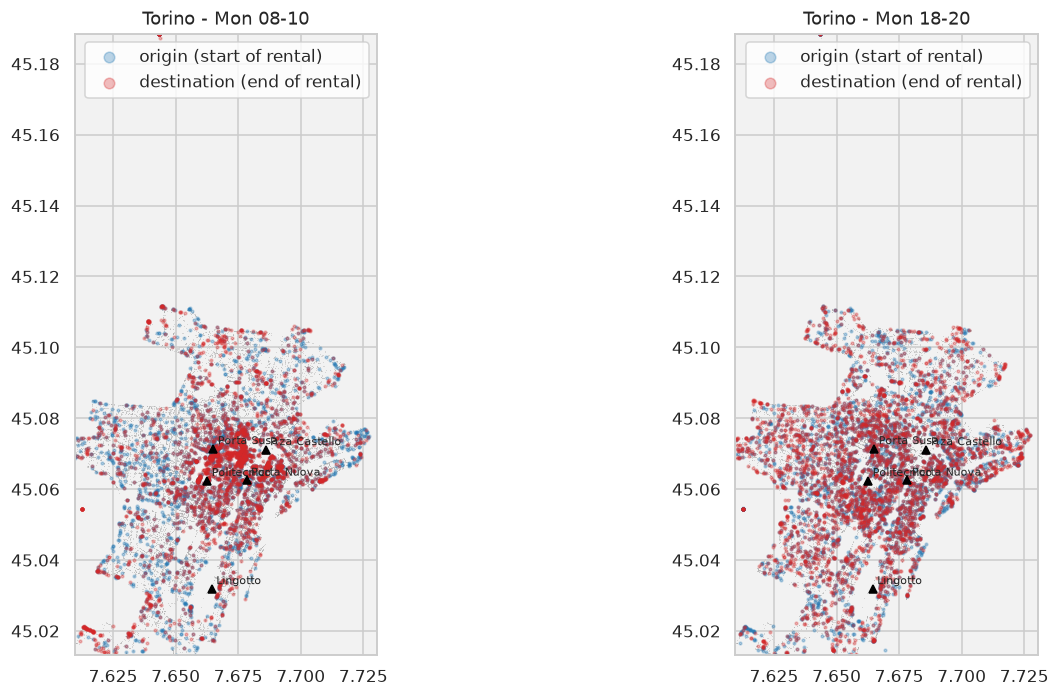

,window,type,lat,lon,rentals/day
0,Mon 08-10,generation,45.0694,7.6636,12.89
1,Mon 08-10,generation,45.0694,7.6764,8.67
2,Mon 08-10,generation,45.0739,7.6700,8.00
3,Mon 08-10,generation,45.0739,7.6764,7.67
4,Mon 08-10,generation,45.0650,7.6891,7.33
5,Mon 08-10,generation,45.0605,7.6764,7.22
6,Mon 08-10,generation,45.0650,7.6700,4.89
7,Mon 08-10,generation,45.0650,7.6827,4.56
8,Mon 08-10,generation,45.0605,7.6573,4.33
9,Mon 08-10,generation,45.0605,7.6700,4.11


In [26]:
# 2.7a - raw origin / destination positions (scatter) for the two Monday windows
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (lbl, (Ho, Hd, o, d)) in zip(axs, (("Mon 08-10", res_a[0]), ("Mon 18-20", res_a[1]))):
    ax.set_xlim(LON0, LON1); ax.set_ylim(LAT0, LAT1); ax.set_aspect(1 / np.cos(np.radians(latc)))
    add_basemap(ax)
    os_, ds_ = o.sample(min(len(o), 8000), random_state=1), d.sample(min(len(d), 8000), random_state=1)
    ax.scatter(os_.lon0, os_.lat0, s=3, alpha=.3, c="tab:blue", label="origin (start of rental)")
    ax.scatter(ds_.lon1, ds_.lat1, s=3, alpha=.3, c="tab:red", label="destination (end of rental)")
    mark_landmarks(ax)
    ax.set_xlim(LON0, LON1); ax.set_ylim(LAT0, LAT1)
    ax.set_title(f"{CITY1} - {lbl}"); ax.legend(markerscale=4, loc="upper right")
plt.tight_layout(); savefig("step2_7_scatter_od"); plt.show()

# trip generation / attraction tables: top-10 zones in the two Monday windows
cl = lambda E: (E[:-1] + E[1:]) / 2
rows = []
for lbl, (Ho, Hd, o, d) in (("Mon 08-10", res_a[0]), ("Mon 18-20", res_a[1])):
    for nm, H in (("generation", Ho), ("attraction", Hd)):
        for k in np.argsort(H.ravel())[::-1][:10]:
            a, b = np.unravel_index(k, H.shape)
            rows.append({"window": lbl, "type": nm, "lat": round(cl(LAT_E)[a], 4), "lon": round(cl(LON_E)[b], 4), "rentals/day": round(H[a, b], 2)})
top = pd.DataFrame(rows); display(top); top.to_csv("tables/step2_7_top_zones.csv", index=False)

In [27]:
# Optional: interactive heatmap (not for the report - open the HTML in a browser)
try:
    import folium
    from folium.plugins import HeatMap
    Ho, Hd, o, d = res_a[1]
    m = folium.Map(location=[latc, (LON0 + LON1) / 2], zoom_start=13, tiles="OpenStreetMap")
    HeatMap(d.sample(min(len(d), 20000), random_state=1)[["lat1", "lon1"]].values.tolist(), radius=8, blur=12).add_to(m)
    m.save("figures/heatmap_destinations_mon_18_20.html"); print("saved figures/heatmap_destinations_mon_18_20.html")
except ImportError:
    print("folium not installed - skipped")

saved figures/heatmap_destinations_mon_18_20.html


## 3. Summary of the choices (copy into the report)

In [28]:
final = pd.DataFrame({"d_min [m]": D_MIN, "T_max [min]": {c: round(v, 1) for c, v in T_MAX.items()}, "P_max [min]": {c: round(v, 1) for c, v in P_MAX.items()},
                      "fleet (median weekly)": FLEET, "outage days": {c: len(OUTAGE[c]) for c in MY_CITIES}})
display(final); display(PARAMS); final.to_csv("tables/final_thresholds.csv")

,d_min [m],T_max [min],P_max [min],fleet (median weekly),outage days
Torino,50.0,995.8,inf,404.0,13
Columbus,50.0,1440.0,inf,188.0,12
Frankfurt,50.0,1356.9,inf,235.0,13


{'T_MIN': 1.0,
 'V_MAX': 120.0,
 'T_MAX_PCT': 99.5,
 'T_MAX_CAP_MIN': 1440,
 'P_MIN': 1.0,
 'P_MAX_PCT': None}